In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

### Objetivo

Implementar un agente de RL que aprenda a invertir en un entorno simulado con un único activo.

### Definición del entorno

El **estado** (observación) es una tupla de la forma ``(tendencia, posición)`` en la que:

- ``tendencia`` es la tendencia del precio, calculada a partir de las últimas 6 observaciones.

- ``posición`` es $1$ si el agente posee el activo y $0$ si no lo posee.

En cada momento, las **acciones** son:

- $0$ = vender

- $1$ = mantener

- $2$ = comprar

Obviamente, la acción *vender* sólo tendrá efecto si el agente es poseedor del activo, y la acción *comprar* sólo tendrá efecto cuando el agente no posee el activo.


In [2]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

### Funciones para generar precios

Se proponen cuatro funciones generadoras de precios. Las pruebas deben hacerse al menos con estas cuatro funciones. Si se desea, pueden añadirse otras funciones de diferentes características, o incluso probar con alguna serie de precios real.

#### 1. Tendencia suave + componente cíclica

In [3]:
def generar_precios(n_steps=1000):
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

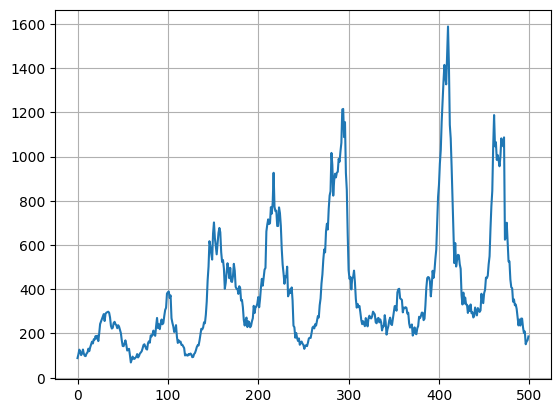

In [4]:
precios = generar_precios(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 2. Movimiento browniano

In [5]:
def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = np.random.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

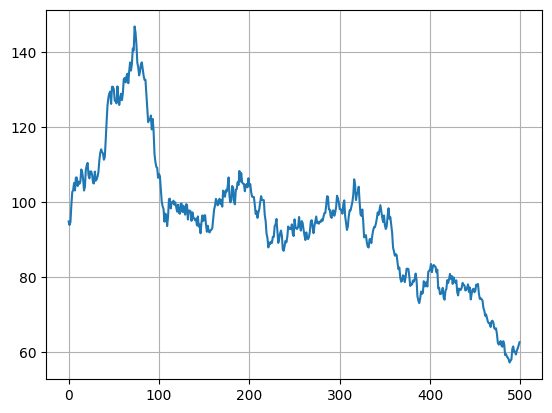

In [6]:
precios = generar_precios_browniano(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 3. Reversión a la media

In [7]:
def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

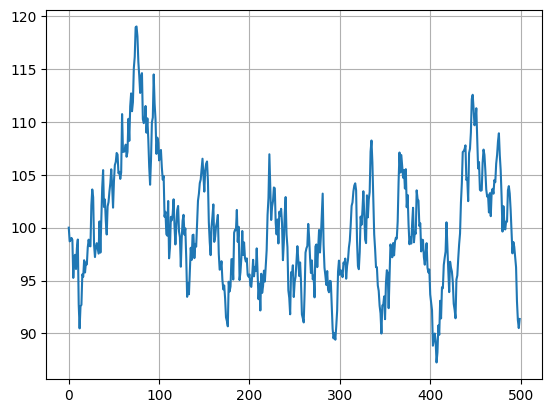

In [8]:
precios = generar_precios_reversion_media(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 4. Alternancia entre regímenes alcistas y bajistas

In [9]:
def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if np.random.rand() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = np.random.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = np.random.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios

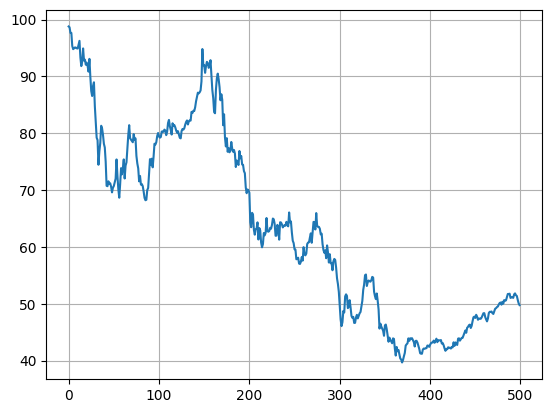

In [10]:
precios = generar_precios_regimenes(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

### Agente aleatorio

Como línea base, se proporciona un agente aleatorio que en cada instante selecciona la acción al azar. A continuación se compara su rendimiento en un episodio con la estrategia *buy & hold*.

In [11]:
n_steps = 500
prices = generar_precios(n_steps)
env = SimpleTradingEnv(prices)

obs, info = env.reset()
terminated = False
step_count = 0

balances = [env.balance]
actions_taken = []
positions = []

while not terminated:
    action = env.action_space.sample()
    positions.append(env.position)
    actions_taken.append(action)

    obs, reward, terminated, truncated, info = env.step(action)
    balances.append(env.balance)

positions = np.array(positions)
actions_taken = np.array(actions_taken)
valid_prices = prices[5:-1]

In [12]:
prices_on = valid_prices.copy()
prices_on[positions==0] = np.nan
prices_off = valid_prices.copy()
prices_off[positions==1] = np.nan

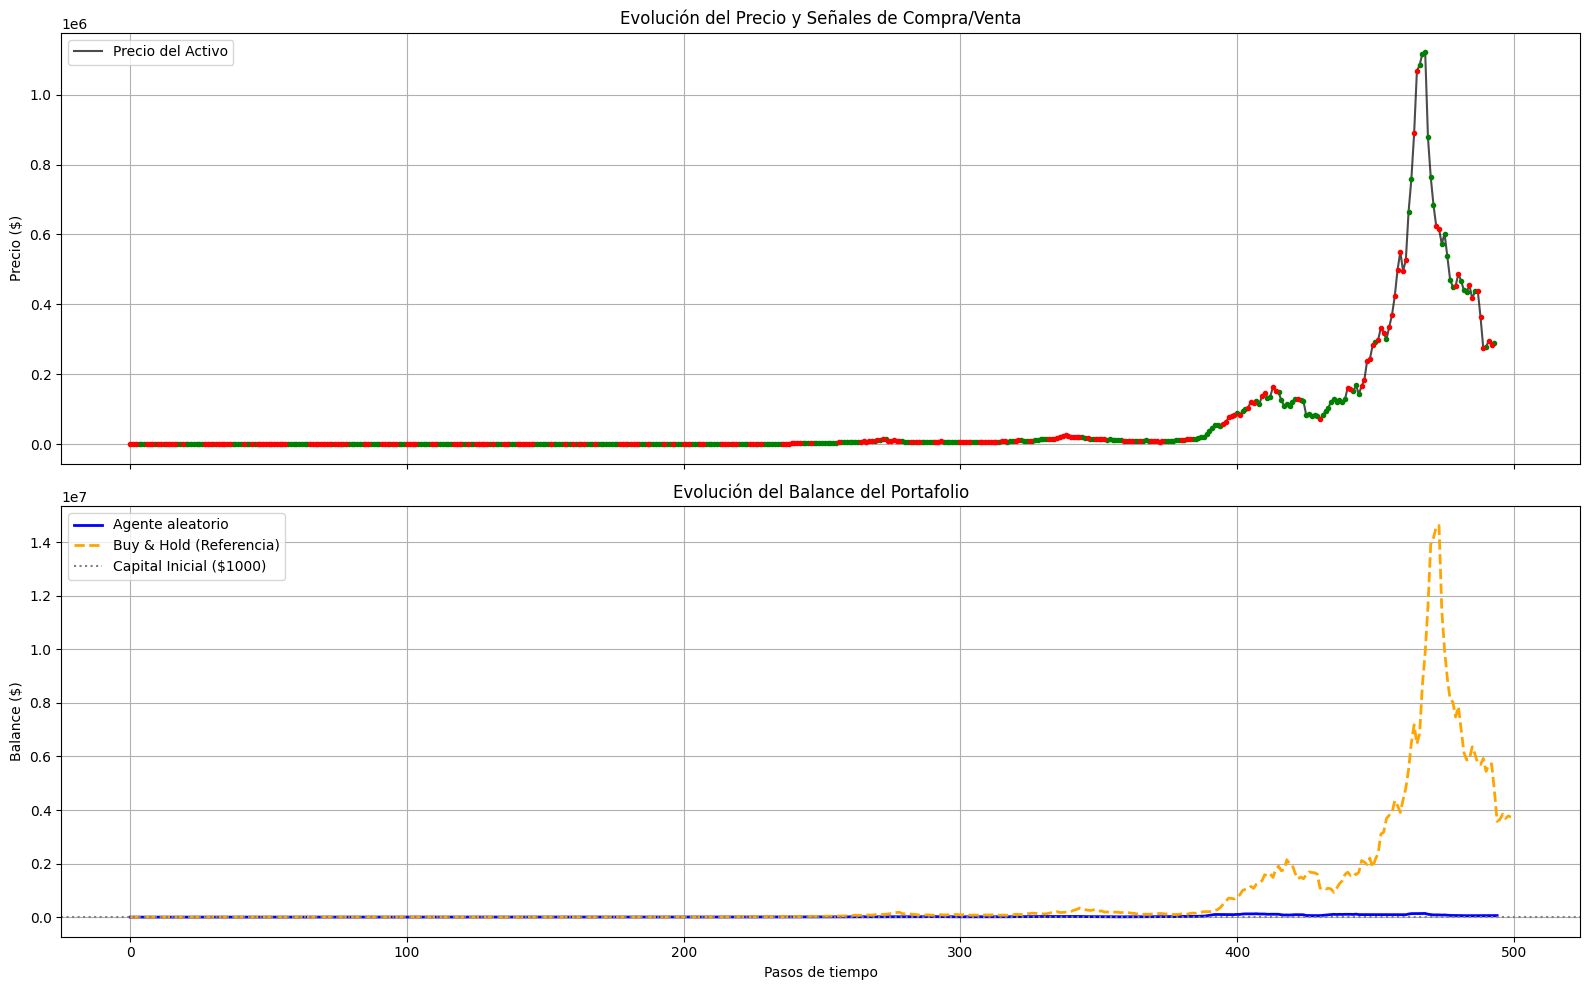

In [13]:
# --- Estrategia Buy & Hold para el panel de balance ---
bh_initial_cash = 1000.0
bh_start_price = prices[5]
bh_shares = (bh_initial_cash * 0.999) / bh_start_price
bh_balances = [bh_initial_cash if i < 5 else bh_shares * p for i, p in enumerate(prices)]

# --- Crear la figura con 2 Subgráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PANEL 1: Evolución del precio y señales de Trading
ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
ax1.plot(prices_on, 'g.')
ax1.plot(prices_off, 'r.')
ax1.set_title("Evolución del Precio y Señales de Compra/Venta")
ax1.set_ylabel("Precio ($)")
ax1.legend(loc="upper left")
ax1.grid(True)

# PANEL 2: Evolución del Balance (Portafolio)
ax2.plot(balances, label="Agente aleatorio", color="blue", linewidth=2)
ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")

ax2.set_title("Evolución del Balance del Portafolio")
ax2.set_xlabel("Pasos de tiempo")
ax2.set_ylabel("Balance ($)")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

### Ejercicios y notas sobre la implementación

1. Implementar los algoritmos vistos en clase y probarlos con distintas funciones de generación de los precios. Deben implementarse al menos los algoritmos *Q-Learning* y *Sarsa*, usando al menos las cuatro funciones de generación de precio propuestas.

   - Cada agente debe entrenarse con varios (muchos) episodios, y cada episodio debería usar una serie de precios distinta, aunque todas deberían ser generadas por la misma función. De este modo el agente puede aprender las regularidades de cada tipo de *mercado* sin repetir siempre los mismos datos para entrenar.

   - Para evaluar los agentes entrenados, se deberían usar datos de *test*, series de precios nuevas generadas a partir de la misma función usada durante el entrenamiento. Los resultados deberían promediarse sobre varias series de test.

2. Analizar las soluciones obtenidas para cada función de generación de precios, y compararlas con el agente aleatorio y con la estrategia *buy & hold*. Razonar si la estrategia encontrada en cada caso es la esperada.

3. Ajustar de manera adecuada los hiperparámetros de cada modelo, en particular el factor de aprendizaje $\alpha$, la tasa de exploración $\epsilon$ (probablemente con decaimiento temporal), el factor de descuento $\gamma$, y el número de episodios de entrenamiento.

4. Comparar en una tabla las soluciones obtenidas con cada algoritmo, incluyendo los *baselines*, sobre cada problema (función generadora de precios). Analizar al menos el rendimiento y el tiempo de convergencia.



### Entrega

Debe entregarse un documento en pdf de un **máximo de dos páginas** con un resumen de las pruebas realizadas, los resultados obtenidos y las conclusiones extraidas.

Las entregas se harán por grupos. Cada grupo de TFM realizará una entrega.

La fecha tope para la entrega es el **29/10/2026**, a las **23:59**.

**Importante:** Una primera versión del documento se deberá entregar por e-mail a luis.lago@uam.es antes de la clase del jueves 29 de octubre. En dicha clase cada grupo presentará su trabajo y lo discutirá con el profesor durante un máximo de 15 minutos. Los comentarios recibidos pueden usarse para mejorar el documento para la entrega final.

De cara a organizar las presentaciones, un representante de cada grupo debe enviar un e-mail al profesor antes del martes 27 de octubre. Ese mismo día os indicaré, mediante mensaje a los representantes, el orden de presentación.

### Evaluación

La realización de los ejercicios y pruebas propuestos garantiza el aprobado en la práctica (50%). El otro 50% se obtendrá valorando la realización de pruebas que vayan más allá de los mínimos planteados (10%), la calidad de presentación de los resultados (20%), la justificación de las decisiones de diseño tomadas (10%) y el análisis crítico de las soluciones obtenidas (10%).

---
# Solución

Esta segunda parte del notebook resuelve los cuatro ejercicios. El orden de las secciones sigue la lógica del trabajo más que la numeración del enunciado:

| Sección | Contenido | Ejercicio |
|---|---|---|
| 0 | Diseño experimental: representación del estado, particiones train/validación/test, métricas | — |
| 1 | Implementación de Q-Learning y SARSA (y, como extra, Expected SARSA y Double Q-Learning) y primera prueba con hiperparámetros "de libro" | 1 |
| 2 | Ajuste de hiperparámetros $\alpha$, $\gamma$, $\epsilon$ y nº de episodios **sobre validación** | 3 |
| 3 | Entrenamiento final con los hiperparámetros elegidos, evaluación sobre **test** y análisis de las políticas aprendidas frente a los *baselines* | 2 |
| 4 | Tabla comparativa de rendimiento y convergencia | 4 |
| 5 | Pruebas adicionales: granularidad del estado, estado ampliado con volatilidad, generalización entre mercados | extra |
| 6 | Conclusiones y análisis crítico | — |

> **Nota sobre el tiempo de ejecución.** Todos los experimentos se ejecutan en paralelo con `joblib` y sus resultados se guardan en la carpeta `resultados/`. Si los ficheros existen, se cargan en lugar de recalcularse (poner `RECALCULAR = True` para repetirlo todo; desde cero tarda del orden de 30-40 minutos en una CPU de 16 hilos).

## 0. Diseño experimental

### 0.1 Representación del estado

El entorno devuelve una observación **continua** `(tendencia, posición)`. Los métodos tabulares necesitan un conjunto finito de estados, así que discretizamos la tendencia en `n_bins` intervalos:

* **Intervalos por cuantiles y por mercado.** La escala de la tendencia cambia mucho de un mercado a otro (en el mercado 1, con un ruido del 10 % por paso, la tendencia vive en $\pm 0.2$; en los otros tres en $\pm 0.04$). Si usáramos intervalos fijos de anchura constante sobre $[-1, 1]$ casi todas las observaciones caerían en uno o dos intervalos. Calculando los límites como cuantiles de la tendencia observada en 50 series del propio mercado, cada intervalo recibe aproximadamente el mismo número de visitas, lo que equilibra el aprendizaje entre estados.
* Con `n_bins = 7` (valor por defecto, estudiado en la sección 5.1) el espacio de estados tiene $7 \times 2 = 14$ estados y la tabla $Q$ tiene $14 \times 3 = 42$ valores.

### 0.2 Particiones de datos

Siguiendo el enunciado, cada episodio de entrenamiento usa una serie **nueva** generada por la misma función. Además separamos tres conjuntos independientes (semillas distintas):

| Conjunto | Uso | Tamaño |
|---|---|---|
| Entrenamiento | Una serie nueva por episodio | 1 serie/episodio |
| Validación | Selección de hiperparámetros y curvas de aprendizaje | 100 series fijas |
| Test | Evaluación final (sólo se usa en las secciones 3-5) | 200 series fijas |

Separar validación y test evita el sesgo optimista de elegir hiperparámetros con los mismos datos con los que luego se informa del resultado. Todas las estrategias se evalúan sobre **las mismas** series de test, de modo que las comparaciones son pareadas.

### 0.3 Métricas

Las series del mercado 1 crecen de forma explosiva (un *buy & hold* multiplica el capital por $\sim 30$), así que la media aritmética del balance final está dominada por unas pocas series. Por eso usamos como métrica principal el **log-retorno** $\log(B_T / B_0)$ medio, que es aditivo y equivale a la rentabilidad geométrica ($e^{\overline{\log r}} - 1$). Además reportamos el balance final mediano, el *drawdown* máximo, el número de operaciones, el porcentaje de tiempo invertido y el porcentaje de series en las que la estrategia supera al *buy & hold*.

In [14]:
import os, time, pickle, itertools
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view
from joblib import Parallel, delayed

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

N_JOBS = -1           # núcleos para joblib (-1 = todos)
RECALCULAR = False    # True para ignorar la caché de resultados
DIR_RES = "resultados"
os.makedirs(DIR_RES, exist_ok=True)

N_STEPS = 500         # longitud de cada serie de precios
MERCADOS = {
    "ciclo":     generar_precios,
    "browniano": generar_precios_browniano,
    "reversion": generar_precios_reversion_media,
    "regimenes": generar_precios_regimenes,
}
NOMBRES = {
    "ciclo": "1. Tendencia + ciclo",
    "browniano": "2. Browniano",
    "reversion": "3. Reversión a la media",
    "regimenes": "4. Regímenes",
}
SEED_DISC, SEED_VAL, SEED_TEST = 12345, 555, 999   # semillas de los conjuntos fijos
N_VAL, N_TEST = 100, 200


def cache(nombre, funcion):
    # Ejecuta `funcion()` sólo si su resultado no está ya guardado en disco
    ruta = os.path.join(DIR_RES, f"{nombre}.pkl")
    if os.path.exists(ruta) and not RECALCULAR:
        with open(ruta, "rb") as f:
            return pickle.load(f)
    t0 = time.perf_counter()
    res = funcion()
    print(f"[{nombre}] calculado en {time.perf_counter() - t0:.0f} s")
    with open(ruta, "wb") as f:
        pickle.dump(res, f)
    return res


def generar_series(mercado, n, seed):
    # Las funciones del profesor usan el generador global de numpy: fijamos la semilla
    # y restauramos el estado anterior para no interferir con el resto del código
    estado = np.random.get_state()
    np.random.seed(seed)
    series = [MERCADOS[mercado](N_STEPS) for _ in range(n)]
    np.random.set_state(estado)
    return series


VAL = {m: generar_series(m, N_VAL, SEED_VAL) for m in MERCADOS}
TEST = {m: generar_series(m, N_TEST, SEED_TEST) for m in MERCADOS}

In [15]:
def tendencias_serie(prices):
    # Misma fórmula que SimpleTradingEnv._get_obs, vectorizada para toda la serie
    w = sliding_window_view(prices, 6)
    m = w.mean(axis=1)
    return np.clip((w[:, -1] - m) / m, -1.0, 1.0)


class Discretizador:
    # Convierte la observación (tendencia, posición) en un índice de estado entero.
    # estado = 2 * intervalo_tendencia + posición  ->  2 * n_bins estados
    def __init__(self, n_bins=7):
        self.n_bins = n_bins
        self.edges = None

    def ajustar(self, mercado, n_series=50):
        # Límites de los intervalos = cuantiles de la tendencia en series del propio mercado
        tend = np.concatenate([tendencias_serie(p) for p in generar_series(mercado, n_series, SEED_DISC)])
        self.edges = np.quantile(tend, np.linspace(0, 1, self.n_bins + 1)[1:-1])
        return self

    @property
    def n_estados(self):
        return 2 * self.n_bins

    def __call__(self, obs):
        return 2 * int(np.searchsorted(self.edges, obs[0])) + int(obs[1])


# Límites de los intervalos en cada mercado
pd.DataFrame({NOMBRES[m]: Discretizador(7).ajustar(m).edges for m in MERCADOS},
             index=[f"límite {i+1}" for i in range(6)]).T

,límite 1,límite 2,límite 3,límite 4,límite 5,límite 6
1. Tendencia + ciclo,-0.143,-0.068,-0.009,0.047,0.109,0.187
2. Browniano,-0.027,-0.014,-0.005,0.004,0.013,0.026
3. Reversión a la media,-0.026,-0.014,-0.004,0.004,0.014,0.026
4. Regímenes,-0.023,-0.010,-0.003,0.004,0.010,0.020


## 1. Implementación de los algoritmos (Ejercicio 1)

Todos los agentes son **tabulares** y comparten la misma estructura; sólo cambia el *objetivo* (target) de la actualización TD:

$$Q(s,a) \leftarrow Q(s,a) + \alpha \big[\, \underbrace{y}_{\text{target}} - Q(s,a) \big]$$

| Algoritmo | Target $y$ | Tipo |
|---|---|---|
| **Q-Learning** | $r + \gamma \max_{a'} Q(s', a')$ | *off-policy*: aprende la política greedy aunque explore |
| **SARSA** | $r + \gamma\, Q(s', a')$, con $a'$ la acción que realmente se ejecutará ($\epsilon$-greedy) | *on-policy*: aprende el valor de la política que explora |
| Expected SARSA (extra) | $r + \gamma \sum_{a'} \pi(a' \mid s')\, Q(s', a')$ | *on-policy* con menor varianza que SARSA |
| Double Q-Learning (extra) | $r + \gamma\, Q_B\big(s', \arg\max_{a'} Q_A(s', a')\big)$ | corrige el sesgo de sobreestimación del $\max$ |

En el estado terminal el target es simplemente $y = r$.

Detalles de implementación relevantes:

* **Desempate aleatorio** en el $\arg\max$: la tabla empieza a ceros y, sin desempate, el agente elegiría siempre la acción 0.
* **Tasa de aprendizaje.** Además de $\alpha$ constante se ofrece la opción `"visitas"`: $\alpha_{s,a} = \max(0.001,\ N(s,a)^{-0.7})$, que decrece con el número de visitas al par $(s,a)$ (condición de Robbins-Monro), de modo que al principio aprende rápido y al final promedia mucho ruido.
* **Exploración** $\epsilon$-greedy con decaimiento exponencial desde $\epsilon_0$ hasta $\epsilon_{fin}$, alcanzado tras una fracción `frac_eps` de los episodios; después se mantiene constante.

In [16]:
def argmax_aleatorio(q, rng):
    # argmax con desempate aleatorio
    idx = np.flatnonzero(q == q.max())
    return int(idx[0]) if len(idx) == 1 else int(rng.choice(idx))


class AgenteTabular:
    METODOS = ("qlearning", "sarsa", "expected_sarsa", "doubleq")

    def __init__(self, n_estados, metodo="qlearning", alpha=0.1, gamma=0.9, n_acciones=3, seed=0):
        assert metodo in self.METODOS
        self.metodo, self.alpha, self.gamma, self.nA = metodo, alpha, gamma, n_acciones
        self.Q = np.zeros((n_estados, n_acciones))
        self.Q2 = np.zeros((n_estados, n_acciones)) if metodo == "doubleq" else None  # 2ª tabla de Double Q
        self.N = np.zeros((n_estados, n_acciones))   # nº de visitas a cada par (s, a)
        self.rng = np.random.default_rng(seed)

    def valores(self, s):
        # Double Q decide con la suma de las dos tablas
        return self.Q[s] if self.Q2 is None else self.Q[s] + self.Q2[s]

    def tabla(self):
        return self.Q if self.Q2 is None else self.Q + self.Q2

    def elegir_accion(self, s, eps):
        # Política epsilon-greedy
        if self.rng.random() < eps:
            return int(self.rng.integers(self.nA))
        return argmax_aleatorio(self.valores(s), self.rng)

    def _lr(self, s, a):
        self.N[s, a] += 1
        if self.alpha == "visitas":
            return max(0.001, self.N[s, a] ** -0.7)
        return self.alpha

    def actualizar(self, s, a, r, s2, a2, terminal, eps):
        # a2 es la acción que se ejecutará en s2 (sólo la usa SARSA)
        lr, g = self._lr(s, a), self.gamma
        if self.metodo == "doubleq":
            # Se actualiza al azar una de las dos tablas usando la otra para evaluar
            A, B = (self.Q, self.Q2) if self.rng.random() < 0.5 else (self.Q2, self.Q)
            y = r if terminal else r + g * B[s2, argmax_aleatorio(A[s2], self.rng)]
            A[s, a] += lr * (y - A[s, a])
            return
        if terminal:
            y = r
        elif self.metodo == "qlearning":
            y = r + g * self.Q[s2].max()
        elif self.metodo == "sarsa":
            y = r + g * self.Q[s2, a2]
        else:  # expected_sarsa: esperanza bajo la política epsilon-greedy actual
            pi = np.full(self.nA, eps / self.nA)
            pi[np.argmax(self.Q[s2])] += 1 - eps
            y = r + g * pi @ self.Q[s2]
        self.Q[s, a] += lr * (y - self.Q[s, a])


def epsilon(ep, n_ep, eps_ini=1.0, eps_fin=0.01, frac_eps=0.7):
    # Decaimiento exponencial de eps_ini a eps_fin en frac_eps * n_ep episodios
    if frac_eps <= 0 or eps_ini == eps_fin:
        return eps_fin
    k = min(ep / (frac_eps * n_ep), 1.0)
    return eps_ini * (eps_fin / eps_ini) ** k

### Bucle de interacción, *baselines* y evaluación

`ejecutar_episodio` sirve tanto para entrenar como para evaluar cualquier "política": basta con que tenga un método `elegir_accion(estado, eps)`. Así, los *baselines* se evalúan exactamente con el mismo entorno y las mismas comisiones que los agentes:

* **Buy & Hold**: compra en el primer paso y no vuelve a operar (equivale a la referencia del profesor).
* **Aleatorio**: acción uniforme en cada paso (el agente del profesor).
* **Momentum** y **Contrarian** (extra): reglas fijas que mantienen el activo cuando la tendencia es positiva (o negativa, respectivamente). No aprenden nada, pero son las estrategias "esperables" en un mercado con inercia o con reversión, y sirven para juzgar si lo que aprende el agente tiene sentido.

In [17]:
class PoliticaFija:
    # Políticas sin aprendizaje. Reciben la observación cruda (se usan con disc=None)
    def __init__(self, tipo, seed=0):
        self.tipo, self.rng = tipo, np.random.default_rng(seed)

    def elegir_accion(self, obs, eps=0.0):
        if self.tipo == "buy_hold":
            return 2
        if self.tipo == "aleatorio":
            return int(self.rng.integers(3))
        if self.tipo == "momentum":     # dentro si la tendencia es positiva
            return 2 if obs[0] > 0 else 0
        if self.tipo == "contrarian":   # dentro si la tendencia es negativa
            return 2 if obs[0] < 0 else 0
        raise ValueError(self.tipo)


def ejecutar_episodio(env, politica, disc=None, eps=0.0, aprender=False, registrar=False):
    disc = disc or (lambda o: o)
    obs, _ = env.reset()
    s = disc(obs)
    a = politica.elegir_accion(s, eps)
    G, terminal, n_ops, t_dentro = 0.0, False, 0, 0
    balances, posiciones = [env.balance], []
    while not terminal:
        pos_antes = env.position
        obs, r, terminal, _, info = env.step(a)
        s2 = disc(obs)
        a2 = politica.elegir_accion(s2, eps)     # siguiente acción (necesaria para SARSA)
        if aprender:
            politica.actualizar(s, a, r, s2, a2, terminal, eps)
        G += r
        n_ops += int(env.position != pos_antes)
        t_dentro += env.position
        if registrar:
            balances.append(env.balance)
            posiciones.append(env.position)
        s, a = s2, a2
    out = dict(G=G, balance=env.balance, n_ops=n_ops, t_dentro=t_dentro / env.max_steps)
    if registrar:
        b = np.array(balances)
        out.update(balances=b, posiciones=np.array(posiciones),
                   max_dd=float(np.max(1 - b / np.maximum.accumulate(b))))
    return out


def evaluar(politica, series, disc=None, env_cls=SimpleTradingEnv, eps=0.0):
    # Evalúa una política (sin aprender) sobre un conjunto de series y devuelve las métricas por serie
    res = [ejecutar_episodio(env_cls(p), politica, disc, eps=eps, registrar=True) for p in series]
    bal = np.array([r["balance"] for r in res])
    return dict(balance=bal, log_ret=np.log(bal / 1000.0),
                max_dd=np.array([r["max_dd"] for r in res]),
                n_ops=np.array([r["n_ops"] for r in res]),
                t_dentro=np.array([r["t_dentro"] for r in res]))

### Función de entrenamiento

`entrenar` recibe un diccionario de configuración, entrena un agente durante `n_episodios` (cada uno con una serie nueva del mercado) y devuelve sólo datos "planos" (tabla $Q$, tiempos, curvas y métricas) para que puedan enviarse entre procesos y guardarse en disco. Opcionalmente:

* cada `eval_cada` episodios evalúa la política **greedy** actual ($\epsilon = 0$, sin aprender) sobre las 20 primeras series de validación → **curva de aprendizaje** usada para medir la convergencia;
* al final evalúa sobre el conjunto de validación completo y/o sobre el de test.

El estado puede ser el del enunciado (`("tend", n_bins)`) o el estado ampliado con volatilidad de la sección 5.2 (`("vol", n_t, n_v)`).

In [18]:
CFG_BASE = dict(metodo="qlearning", mercado="ciclo", alpha=0.1, gamma=0.9, n_episodios=1000,
                eps_ini=1.0, eps_fin=0.01, frac_eps=0.7, estado=("tend", 7), seed=0)


def crear_estado(spec, mercado):
    # Devuelve (clase de entorno, discretizador ajustado) según la representación del estado
    if spec[0] == "tend":
        return SimpleTradingEnv, Discretizador(spec[1]).ajustar(mercado)
    if spec[0] == "vol":
        return TradingEnvVol, DiscretizadorVol(spec[1], spec[2]).ajustar(mercado)
    raise ValueError(spec)


def entrenar(cfg, val=None, test=None, curva_series=None, eval_cada=None):
    # val / test / curva_series: listas de series de precios (o None). Se pasan explícitamente
    # para que cada proceso de joblib reciba sólo los datos de su mercado
    cfg = {**CFG_BASE, **cfg}
    m = cfg["mercado"]
    env_cls, disc = crear_estado(cfg["estado"], m)
    agente = AgenteTabular(disc.n_estados, cfg["metodo"], cfg["alpha"], cfg["gamma"], seed=cfg["seed"])
    np.random.seed(cfg["seed"])             # semilla de las series de entrenamiento
    n_ep = cfg["n_episodios"]
    G_hist, curva = np.zeros(n_ep), []
    t_train = 0.0
    for ep in range(n_ep):
        t0 = time.perf_counter()
        env = env_cls(MERCADOS[m](N_STEPS))
        eps = epsilon(ep, n_ep, cfg["eps_ini"], cfg["eps_fin"], cfg["frac_eps"])
        G_hist[ep] = ejecutar_episodio(env, agente, disc, eps=eps, aprender=True)["G"]
        t_train += time.perf_counter() - t0  # el tiempo de evaluación no cuenta como entrenamiento
        if eval_cada and ((ep + 1) % eval_cada == 0 or ep == 0):
            rng_estado = agente.rng.bit_generator.state
            v = evaluar(agente, curva_series, disc, env_cls)["log_ret"].mean()
            agente.rng.bit_generator.state = rng_estado   # la evaluación no altera el entrenamiento
            curva.append((ep + 1, v))
    out = dict(cfg=cfg, Q=agente.tabla(), G_hist=G_hist, curva=np.array(curva),
               tiempo=t_train, t_por_ep=t_train / n_ep)
    if val is not None:
        out["val"] = evaluar(agente, val, disc, env_cls)
    if test is not None:
        out["test"] = evaluar(agente, test, disc, env_cls)
    return out


def lanzar(cfgs, val=False, test=False, eval_cada=None, n_val_curva=20):
    # Entrena en paralelo una lista de configuraciones.
    # La curva de aprendizaje usa las primeras n_val_curva series de validación
    def args(c):
        m = c["mercado"]
        return dict(val=VAL[m] if val else None, test=TEST[m] if test else None,
                    curva_series=VAL[m][:n_val_curva] if eval_cada else None, eval_cada=eval_cada)
    return Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(entrenar)(c, **args(c)) for c in cfgs)


class AgenteCongelado:
    # Política greedy a partir de una tabla Q ya entrenada (para re-evaluar agentes guardados)
    def __init__(self, Q, seed=0):
        self.Q, self.rng = Q, np.random.default_rng(seed)

    def elegir_accion(self, s, eps=0.0):
        return argmax_aleatorio(self.Q[s], self.rng)

La clase `TradingEnvVol` y su discretizador se usan en la sección 5.2; se definen aquí porque `crear_estado` los necesita. El entorno **hereda** del del profesor y sólo añade una tercera componente a la observación (la volatilidad de los 5 últimos retornos), sin cambiar la dinámica ni la recompensa.

In [19]:
class TradingEnvVol(SimpleTradingEnv):
    # Mismo entorno, pero la observación incluye la volatilidad reciente: (tendencia, posición, volatilidad)
    def _get_obs(self):
        base = super()._get_obs()
        w = self.prices[self.current_step - 5: self.current_step + 1]
        vol = np.std(np.diff(w) / w[:-1])
        return np.array([base[0], base[1], vol], dtype=np.float32)


class DiscretizadorVol:
    # estado = 2 * (intervalo_tendencia * n_v + intervalo_volatilidad) + posición
    def __init__(self, n_t=5, n_v=3):
        self.n_t, self.n_v = n_t, n_v

    def ajustar(self, mercado, n_series=50):
        T, V = [], []
        for p in generar_series(mercado, n_series, SEED_DISC):
            w = sliding_window_view(p, 6)
            T.append(tendencias_serie(p))
            V.append((np.diff(w, axis=1) / w[:, :-1]).std(axis=1))
        T, V = np.concatenate(T), np.concatenate(V)
        self.edges_t = np.quantile(T, np.linspace(0, 1, self.n_t + 1)[1:-1])
        self.edges_v = np.quantile(V, np.linspace(0, 1, self.n_v + 1)[1:-1])
        return self

    @property
    def n_estados(self):
        return 2 * self.n_t * self.n_v

    def __call__(self, obs):
        bt = int(np.searchsorted(self.edges_t, obs[0]))
        bv = int(np.searchsorted(self.edges_v, obs[2]))
        return 2 * (bt * self.n_v + bv) + int(obs[1])

### Evaluación de los *baselines*

Se evalúan una sola vez sobre validación y test. El agente aleatorio se repite 5 veces por serie (con semillas distintas) para reducir la varianza de su estimación.

In [20]:
def evaluar_baselines(conjunto):
    out = {}
    for m in MERCADOS:
        series = conjunto[m]
        out[m] = {t: evaluar(PoliticaFija(t), series) for t in ["buy_hold", "momentum", "contrarian"]}
        reps = [evaluar(PoliticaFija("aleatorio", seed=k), series) for k in range(5)]
        out[m]["aleatorio"] = {k: np.mean([r[k] for r in reps], axis=0) for k in reps[0]}
    return out

BASE_VAL = cache("baselines_val", lambda: evaluar_baselines(VAL))
BASE_TEST = cache("baselines_test", lambda: evaluar_baselines(TEST))

pd.DataFrame({NOMBRES[m]: {t: BASE_VAL[m][t]["log_ret"].mean() for t in BASE_VAL[m]} for m in MERCADOS}).T \
  .rename(columns=str.capitalize).style.format("{:.3f}").set_caption("Log-retorno medio de los baselines (validación)")

,Buy_hold,Momentum,Contrarian,Aleatorio
1. Tendencia + ciclo,3.516,6.211,-2.880,1.531
2. Browniano,-0.019,-0.079,-0.174,-0.180
3. Reversión a la media,-0.016,-0.298,0.032,-0.169
4. Regímenes,-0.122,-0.178,-0.179,-0.229


**Interpretación de los *baselines*.** Antes de entrenar nada conviene saber qué se puede esperar de cada mercado:

* **Tendencia + ciclo.** Los retornos tienen una deriva creciente y una componente sinusoidal de amplitud 5 % por paso con un periodo de unos 63 pasos. Esa componente hace que los retornos estén **autocorrelacionados**: si el precio ha subido en los últimos pasos es probable que siga subiendo. Por eso *momentum* (≈ 6.2) duplica el log-retorno del *buy & hold* (≈ 3.5, es decir, ×33 el capital) y *contrarian* es desastroso.
* **Browniano.** Los retornos son independientes: el pasado no contiene información sobre el futuro. Cualquier estrategia activa sólo paga comisiones. Es una buena comprobación de la implementación: el agente aleatorio hace ~165 operaciones por episodio, que a 0.1 % cada una suponen ≈ −0.165, justo lo que pierde (−0.18). El *buy & hold* tiene log-retorno esperado $(\mu - \sigma^2/2)\,T = (0.0001 - 0.0002) \cdot 494 \approx -0.05$: ligeramente negativo por el arrastre de la volatilidad.
* **Reversión a la media.** El precio oscila alrededor de 100, así que el *buy & hold* queda en ≈ 0. La señal útil es **contraria**: tras una caída el precio tiende a recuperarse. *Contrarian* gana algo (≈ +0.03 / +0.08) y *momentum* pierde mucho.
* **Regímenes.** El régimen bajista cae más (−0.15 %/paso) y con más volatilidad (2.5 %) de lo que sube el alcista (+0.1 %, 1 %), así que el *buy & hold* pierde (≈ −0.12 / −0.15). Ninguna regla basada sólo en el signo de la tendencia obtiene beneficio (*momentum* apenas mejora al B&H en test y empeora en validación): la tendencia de 6 pasos es demasiado ruidosa para identificar el régimen. En este mercado, **no invertir (log-retorno 0) ya es mejor que todos los *baselines***.

### 1.1 Primera prueba: hiperparámetros "de libro"

Antes de ajustar nada entrenamos Q-Learning y SARSA con valores típicos de los ejemplos de clase ($\alpha = 0.1$, $\gamma = 0.9$, $\epsilon$: $1 \to 0.01$, 1000 episodios) en los cuatro mercados.

In [21]:
def exp_inicial():
    cfgs = [dict(metodo=a, mercado=m, alpha=0.1, gamma=0.9, n_episodios=1000, seed=s)
            for a in ["qlearning", "sarsa"] for m in MERCADOS for s in range(3)]
    return lanzar(cfgs, val=True, eval_cada=50)

R_INI = cache("exp_inicial", exp_inicial)


def tabla_resumen_val(resultados):
    filas = []
    for r in resultados:
        c = r["cfg"]
        filas.append(dict(mercado=NOMBRES[c["mercado"]], algoritmo=c["metodo"], seed=c["seed"],
                          log_ret=r["val"]["log_ret"].mean(), t_dentro=r["val"]["t_dentro"].mean()))
    df = pd.DataFrame(filas).groupby(["mercado", "algoritmo"])[["log_ret", "t_dentro"]].mean()
    clave = {v: k for k, v in NOMBRES.items()}
    df["B&H"] = [BASE_VAL[clave[n]]["buy_hold"]["log_ret"].mean() for n in df.index.get_level_values("mercado")]
    return df

tabla_resumen_val(R_INI)

log_ret  t_dentro    B&H
mercado                 algoritmo                          
1. Tendencia + ciclo    qlearning    4.055     0.276  3.516
                        sarsa        5.114     0.387  3.516
2. Browniano            qlearning    0.000     0.000 -0.019
                        sarsa        0.000     0.000 -0.019
3. Reversión a la media qlearning    0.000     0.000 -0.016
                        sarsa        0.000     0.000 -0.016
4. Regímenes            qlearning    0.000     0.000 -0.122
                        sarsa        0.000     0.000 -0.122

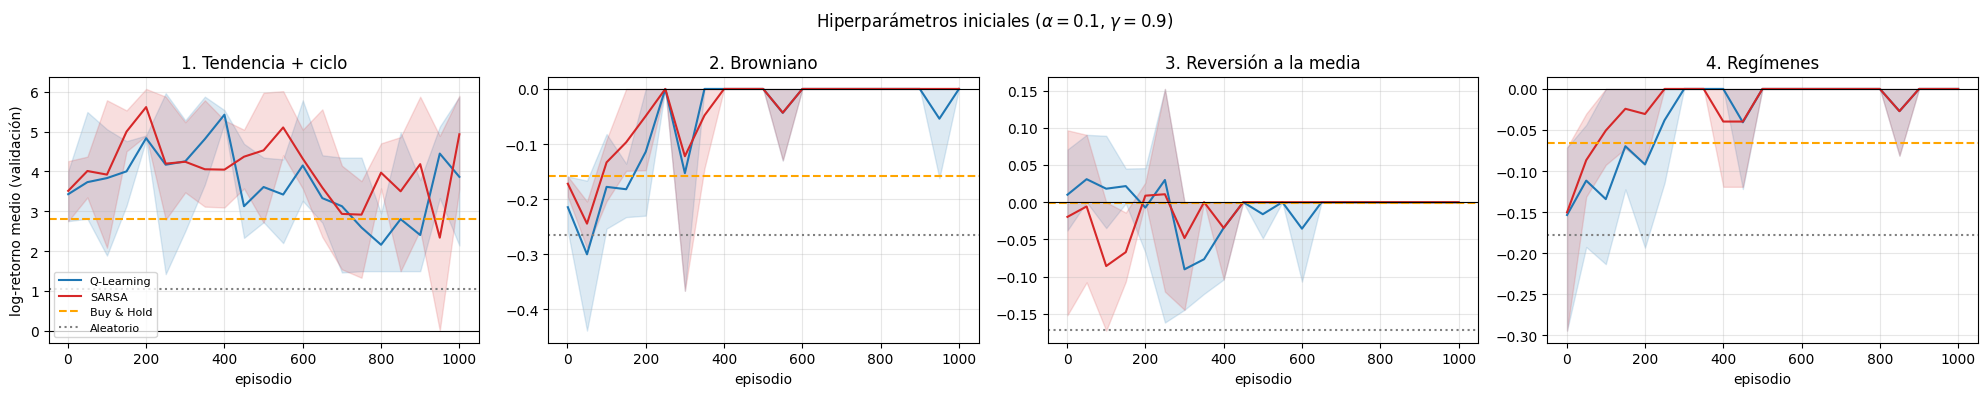

In [22]:
COLORES = {"qlearning": "tab:blue", "sarsa": "tab:red", "expected_sarsa": "tab:green", "doubleq": "tab:purple"}
ETIQUETAS = {"qlearning": "Q-Learning", "sarsa": "SARSA", "expected_sarsa": "Expected SARSA", "doubleq": "Double Q"}


def plot_curvas(resultados, titulo, n_val_curva=20):
    # Curva de aprendizaje: log-retorno de la política greedy en validación (media ± rango entre semillas)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for ax, m in zip(axes, MERCADOS):
        for alg in COLORES:
            rs = [r for r in resultados if r["cfg"]["mercado"] == m and r["cfg"]["metodo"] == alg]
            if not rs:
                continue
            x = rs[0]["curva"][:, 0]
            Y = np.array([r["curva"][:, 1] for r in rs])
            ax.plot(x, Y.mean(0), color=COLORES[alg], label=ETIQUETAS[alg])
            ax.fill_between(x, Y.min(0), Y.max(0), color=COLORES[alg], alpha=0.15)
        ax.axhline(BASE_VAL[m]["buy_hold"]["log_ret"][:n_val_curva].mean(), color="orange", ls="--", label="Buy & Hold")
        ax.axhline(BASE_VAL[m]["aleatorio"]["log_ret"][:n_val_curva].mean(), color="gray", ls=":", label="Aleatorio")
        ax.axhline(0, color="black", lw=0.8)
        ax.set_title(NOMBRES[m]); ax.set_xlabel("episodio")
    axes[0].set_ylabel("log-retorno medio (validación)")
    axes[0].legend(fontsize=8)
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

plot_curvas(R_INI, r"Hiperparámetros iniciales ($\alpha=0.1$, $\gamma=0.9$)")

**Interpretación.** Con $\alpha = 0.1$ los resultados son malos e inestables:

* En el **mercado cíclico** el agente supera al *buy & hold* en media, pero la curva oscila mucho y el resultado final depende enormemente de la semilla (log-retorno de validación entre 2.5 y 6.1).
* En los **otros tres mercados** las tres semillas de ambos algoritmos acaban en la misma política: **no comprar nunca** (log-retorno exactamente 0, tiempo invertido 0 %).

La causa es la **relación señal/ruido**. La ventaja esperada que se puede explotar en estos mercados es del orden de 0.1 % por paso, mientras que la desviación típica del retorno de un paso es de 1-2.5 % (10 % en el mercado cíclico). Con $\alpha$ constante, $Q(s,a)$ es una media móvil exponencial con una "ventana efectiva" de $\approx 1/\alpha = 10$ muestras, cuya desviación típica es $\sigma\sqrt{\alpha/(2-\alpha)} \approx 0.23\,\sigma \approx 0.5\,\%$, cinco veces mayor que la señal que queremos estimar. Con $\gamma = 0.9$ el *target* además acumula el ruido de unos 10 retornos futuros.

¿Por qué el error se concentra en "quedarse fuera"? Porque el valor de *esperar sin activo* es **determinista** (recompensa 0 exacta), mientras que el de *comprar* es ruidoso y empieza con −0.1 % de comisión: en cuanto una mala racha lo hace negativo, el agente greedy deja de comprar y los estados "con activo" sólo se vuelven a visitar por exploración. Es necesario un $\alpha$ mucho menor (ventana de cientos o miles de muestras), lo que motiva el ajuste de la sección siguiente.

## 2. Ajuste de hiperparámetros (Ejercicio 3)

El ajuste se hace **sólo con el conjunto de validación** y por etapas (búsqueda coordinada), porque una rejilla completa sobre los cuatro hiperparámetros sería muy costosa:

1. Rejilla $\alpha \times \gamma$ con la exploración por defecto y 1500 episodios.
2. Con el mejor $(\alpha, \gamma)$ de cada mercado y algoritmo, comparamos varias estrategias de exploración $\epsilon$.
3. Con todo lo anterior fijo, estudiamos cuántos episodios hacen falta.

Cada configuración se entrena con 2 semillas y se evalúa sobre las 100 series de validación; el criterio es el log-retorno medio.

### 2.1 Factor de aprendizaje $\alpha$ y factor de descuento $\gamma$

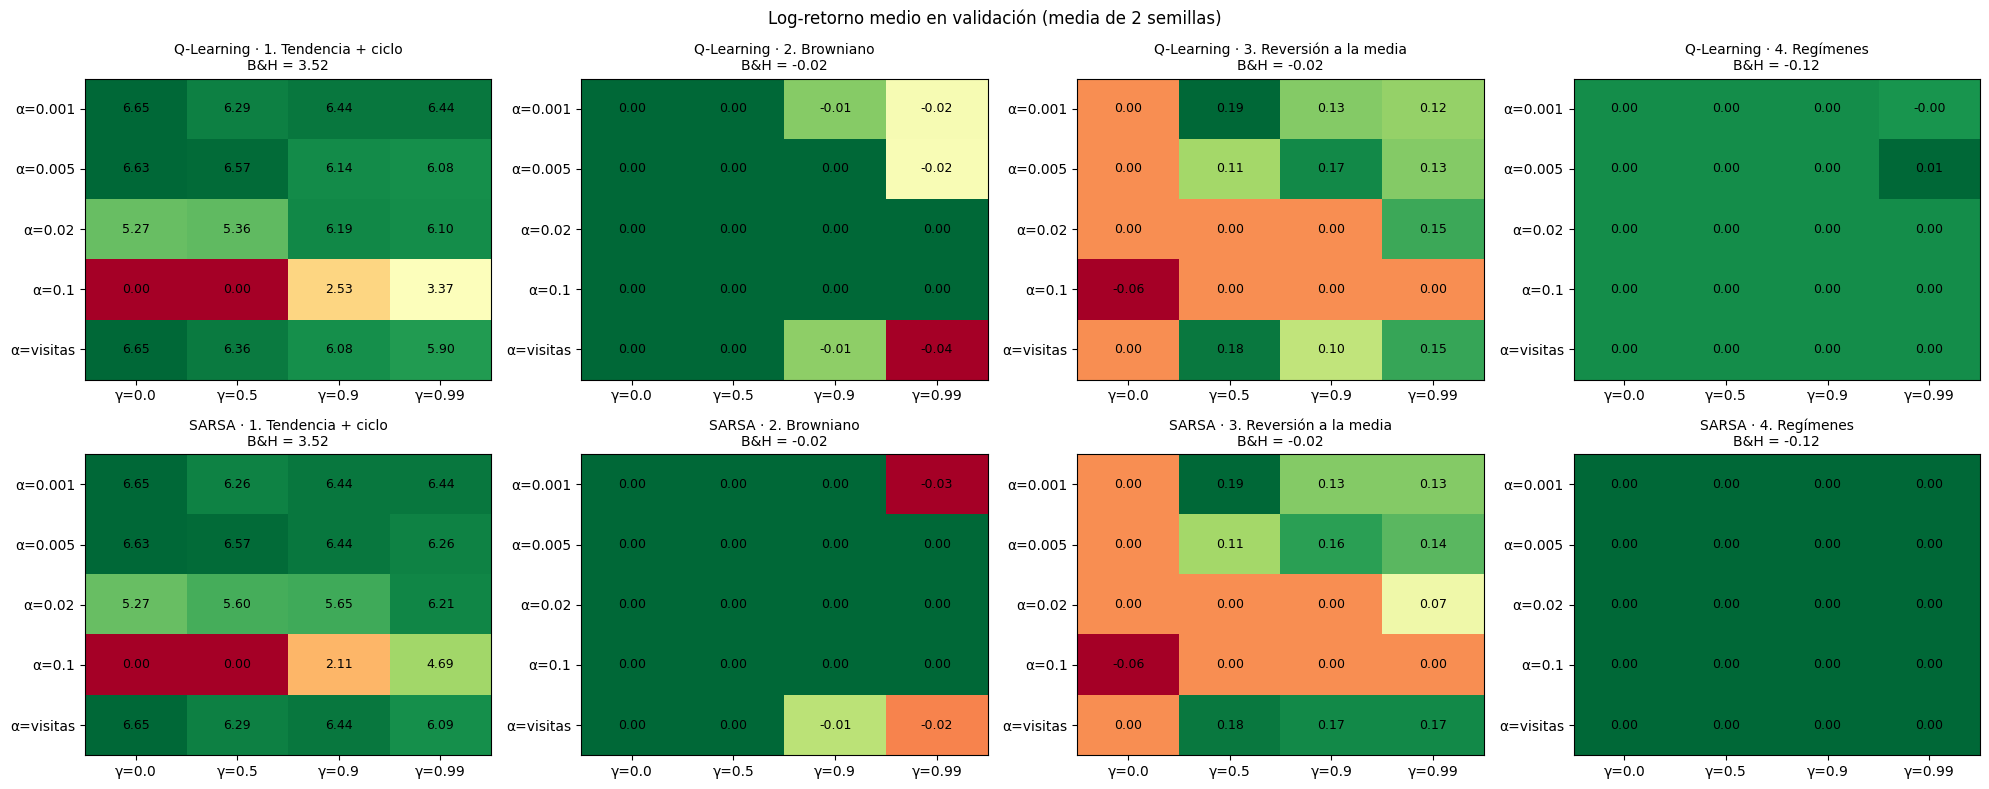

In [23]:
ALPHAS = [0.001, 0.005, 0.02, 0.1, "visitas"]
GAMMAS = [0.0, 0.5, 0.9, 0.99]

def exp_grid():
    cfgs = [dict(metodo=a, mercado=m, alpha=al, gamma=g, n_episodios=1500, seed=s)
            for a in ["qlearning", "sarsa"] for m in MERCADOS for al in ALPHAS for g in GAMMAS for s in range(2)]
    return lanzar(cfgs, val=True)

R_GRID = cache("exp_grid", exp_grid)

df_grid = pd.DataFrame([dict(algoritmo=r["cfg"]["metodo"], mercado=r["cfg"]["mercado"], alpha=str(r["cfg"]["alpha"]),
                             gamma=r["cfg"]["gamma"], seed=r["cfg"]["seed"], log_ret=r["val"]["log_ret"].mean())
                        for r in R_GRID])
grid_medio = df_grid.groupby(["algoritmo", "mercado", "alpha", "gamma"])["log_ret"].mean()

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, alg in enumerate(["qlearning", "sarsa"]):
    for j, m in enumerate(MERCADOS):
        tabla = grid_medio.loc[alg, m].unstack("gamma").loc[[str(a) for a in ALPHAS]]
        ax = axes[i, j]
        # Escala de color común a la celda y a B&H; si todos los valores son iguales se usa un color neutro
        lo = min(tabla.values.min(), BASE_VAL[m]["buy_hold"]["log_ret"].mean())
        hi = max(tabla.values.max(), lo + 0.02)
        ax.imshow(tabla.values, cmap="RdYlGn", aspect="auto", vmin=lo, vmax=hi)
        for (y, x), v in np.ndenumerate(tabla.values):
            ax.text(x, y, f"{v:.2f}", ha="center", va="center", fontsize=9)
        ax.set_xticks(range(len(GAMMAS)), [f"γ={g}" for g in GAMMAS])
        ax.set_yticks(range(len(ALPHAS)), [f"α={a}" for a in ALPHAS])
        ax.set_title(f"{ETIQUETAS[alg]} · {NOMBRES[m]}\nB&H = {BASE_VAL[m]['buy_hold']['log_ret'].mean():.2f}", fontsize=10)
        ax.grid(False)
fig.suptitle("Log-retorno medio en validación (media de 2 semillas)")
plt.tight_layout(); plt.show()

In [24]:
# Mejor (alpha, gamma) para cada algoritmo y mercado
MEJOR = {}
for (alg, m), g in grid_medio.groupby(level=["algoritmo", "mercado"]):
    (_, _, al, ga) = g.idxmax()
    MEJOR[(alg, m)] = dict(alpha=al if al == "visitas" else float(al), gamma=ga)

pd.DataFrame([dict(algoritmo=ETIQUETAS[a], mercado=NOMBRES[m], **v,
                   log_ret_val=grid_medio.loc[(a, m, str(v["alpha"]), v["gamma"])]) for (a, m), v in MEJOR.items()])

,algoritmo,mercado,alpha,gamma,log_ret_val
0,Q-Learning,2. Browniano,0.001,0.00,0.000
1,Q-Learning,1. Tendencia + ciclo,0.001,0.00,6.647
2,Q-Learning,4. Regímenes,0.005,0.99,0.011
3,Q-Learning,3. Reversión a la media,0.001,0.50,0.189
4,SARSA,2. Browniano,0.001,0.00,0.000
5,SARSA,1. Tendencia + ciclo,0.001,0.00,6.647
6,SARSA,4. Regímenes,0.001,0.00,0.000
7,SARSA,3. Reversión a la media,0.001,0.50,0.189


**Interpretación de la rejilla $\alpha \times \gamma$** (el color es relativo a cada panel; el valor de B&H está en el título):

* **$\alpha$.** Los mejores resultados aparecen siempre con $\alpha \in \{0.001, 0.005\}$ o con la tasa decreciente por visitas, y $\alpha = 0.1$ es claramente el peor valor en los mercados con estructura (ciclo y reversión), lo que confirma el diagnóstico de la sección 1.1: hay que promediar muchísimas muestras para distinguir la señal del ruido. La opción `"visitas"` rinde casi igual que el mejor $\alpha$ fijo, así que es una buena alternativa cuando no se quiere ajustar este parámetro.
* **$\gamma$ depende del mercado, y tiene sentido:**
  * *Tendencia + ciclo*: el mejor es $\gamma = 0$ (agente **miope**). La rentabilidad esperada del paso siguiente (hasta ±5 %) es muy superior a la comisión (0.1 %), así que basta con decidir paso a paso; un $\gamma$ alto sólo añade varianza al *target*.
  * *Reversión a la media*: con $\gamma = 0$ el agente **no aprende nada** (0.000) y con $\gamma \geq 0.5$ y $\alpha$ pequeño sí (≈ 0.12-0.19). Comprar cuesta 0.1 % *ahora* y la recuperación del precio llega a lo largo de *varios* pasos; sólo un agente que valora el futuro puede ver que la operación compensa.
  * *Regímenes*: sólo con $\gamma = 0.99$ (horizonte de ~100 pasos, comparable a la duración media de un régimen, 50 pasos) Q-Learning consigue algo ligeramente positivo.
  * *Browniano*: casi todas las configuraciones acaban fuera del mercado (0); con $\gamma = 0.99$ el agente aprende a **mantener** el activo y se acerca al *buy & hold* (≈ −0.02). Esto revela un desajuste interesante: la recompensa es la suma de retornos **aritméticos**, cuya esperanza es positiva ($\mu = 0.0001 > 0$), así que para el criterio que optimiza el agente mantener es (marginalmente) óptimo; sin embargo, el capital crece de forma **geométrica** y su log-retorno esperado es negativo por el arrastre de la volatilidad. Optimizar la recompensa no es exactamente optimizar la riqueza final.
* **Q-Learning vs SARSA.** Con $\gamma = 0$ los dos algoritmos son idénticos (el *target* es sólo $r$, no interviene la acción siguiente), y por eso varias columnas coinciden exactamente. Las diferencias aparecen con $\gamma > 0$ y son pequeñas.
* **Advertencia sobre los empates.** Cuando muchas configuraciones dan exactamente 0 (el agente no invierte), `idxmax` elige la primera, que es $(\alpha = 0.001, \gamma = 0)$. Así ocurre con SARSA en regímenes y con ambos algoritmos en browniano: la elección es arbitraria, y lo tendremos en cuenta al interpretar la sección 5.2.

### 2.2 Tasa de exploración $\epsilon$

Comparamos cinco esquemas con el mejor $(\alpha, \gamma)$ de cada caso:

| Esquema | $\epsilon_0$ | $\epsilon_{fin}$ | Fracción de episodios hasta $\epsilon_{fin}$ |
|---|---|---|---|
| `rápido` | 1.0 | 0.01 | 30 % |
| `estándar` (el usado hasta ahora) | 1.0 | 0.01 | 70 % |
| `lento` | 1.0 | 0.01 | 100 % |
| `residual alto` | 1.0 | 0.10 | 70 % |
| `constante` | 0.10 | 0.10 | — |

In [25]:
ESQUEMAS_EPS = {
    "rápido":        dict(eps_ini=1.0, eps_fin=0.01, frac_eps=0.3),
    "estándar":      dict(eps_ini=1.0, eps_fin=0.01, frac_eps=0.7),
    "lento":         dict(eps_ini=1.0, eps_fin=0.01, frac_eps=1.0),
    "residual alto": dict(eps_ini=1.0, eps_fin=0.10, frac_eps=0.7),
    "constante":     dict(eps_ini=0.1, eps_fin=0.10, frac_eps=0.0),
}

def exp_eps():
    cfgs = [dict(metodo=a, mercado=m, n_episodios=1500, seed=s, **MEJOR[(a, m)], **ESQUEMAS_EPS[e], esquema=e)
            for a in ["qlearning", "sarsa"] for m in MERCADOS for e in ESQUEMAS_EPS for s in range(2)]
    return lanzar(cfgs, val=True)

R_EPS = cache("exp_eps", exp_eps)

df_eps = pd.DataFrame([dict(algoritmo=ETIQUETAS[r["cfg"]["metodo"]], mercado=NOMBRES[r["cfg"]["mercado"]],
                            esquema=r["cfg"]["esquema"], log_ret=r["val"]["log_ret"].mean()) for r in R_EPS])
tabla_eps = df_eps.groupby(["mercado", "algoritmo", "esquema"])["log_ret"].mean().unstack("esquema")[list(ESQUEMAS_EPS)]
tabla_eps.style.format("{:.3f}").highlight_max(axis=1, color="#c6efce")

In [26]:
# Mejor esquema de exploración por algoritmo y mercado
for (alg, m) in MEJOR:
    fila = tabla_eps.loc[(NOMBRES[m], ETIQUETAS[alg])]
    MEJOR[(alg, m)]["esquema"] = fila.idxmax()
pd.DataFrame(MEJOR).T

alpha gamma esquema
qlearning browniano  0.001   0.0  rápido
          ciclo      0.001   0.0  rápido
          regimenes  0.005  0.99   lento
          reversion  0.001   0.5  rápido
sarsa     browniano  0.001   0.0  rápido
          ciclo      0.001   0.0  rápido
          regimenes  0.001   0.0  rápido
          reversion  0.001   0.5  rápido

**Interpretación.** La estrategia de exploración prácticamente **no influye** (las diferencias son de milésimas, salvo el esquema constante, que es algo peor en el mercado cíclico y en reversión con Q-Learning). Esto, que puede parecer sorprendente, tiene dos explicaciones propias de este problema:

1. **Las acciones no afectan a la dinámica del mercado.** La tendencia (la parte "grande" del estado) evoluciona igual haga lo que haga el agente, así que todos los intervalos de tendencia se visitan con cualquier política. Sólo la componente *posición* depende de las acciones, y bastan unas pocas acciones aleatorias por episodio para cubrir los dos valores. El dilema exploración-explotación es mucho más suave que en, por ejemplo, un laberinto.
2. **Con $\gamma = 0$** (elegido en varios mercados) Q-Learning y SARSA tienen el mismo *target*, así que la diferencia *on-policy* / *off-policy* (que es donde la exploración cambia lo que se aprende) desaparece.

Como criterio de elección se toma el mejor esquema en validación y, en caso de empate, el primero de la lista (`rápido`).

### 2.3 Número de episodios de entrenamiento

Con $\alpha$, $\gamma$ y $\epsilon$ fijados, entrenamos con presupuestos de 100 a 4000 episodios. El esquema de $\epsilon$ se escala con el presupuesto (la fracción es relativa), así que cada punto es un entrenamiento completo e independiente, no un punto intermedio de una misma curva.

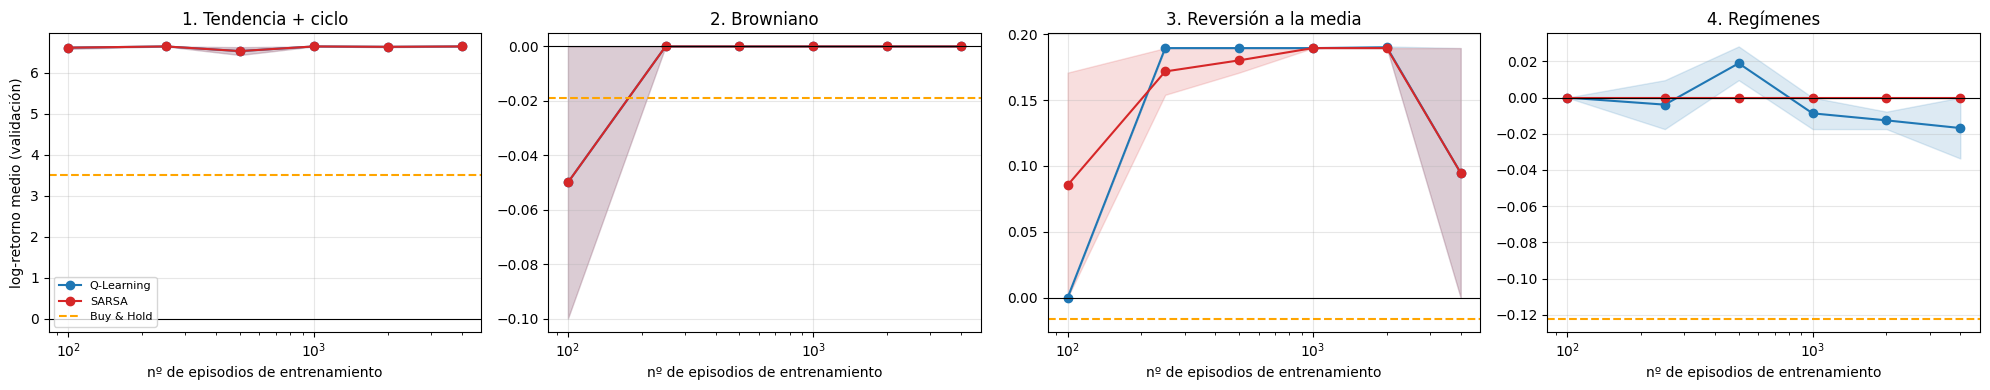

Tiempo medio de entrenamiento por episodio: 27.9 ms


In [27]:
N_EPISODIOS = [100, 250, 500, 1000, 2000, 4000]

def exp_episodios():
    cfgs = [dict(metodo=a, mercado=m, n_episodios=n, seed=s, alpha=MEJOR[(a, m)]["alpha"],
                 gamma=MEJOR[(a, m)]["gamma"], **ESQUEMAS_EPS[MEJOR[(a, m)]["esquema"]])
            for a in ["qlearning", "sarsa"] for m in MERCADOS for n in N_EPISODIOS for s in range(2)]
    return lanzar(cfgs, val=True)

R_NEP = cache("exp_episodios", exp_episodios)

df_nep = pd.DataFrame([dict(algoritmo=r["cfg"]["metodo"], mercado=r["cfg"]["mercado"], n=r["cfg"]["n_episodios"],
                            log_ret=r["val"]["log_ret"].mean(), tiempo=r["tiempo"]) for r in R_NEP])
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, m in zip(axes, MERCADOS):
    for alg in ["qlearning", "sarsa"]:
        d = df_nep[(df_nep.mercado == m) & (df_nep.algoritmo == alg)].groupby("n")["log_ret"].agg(["mean", "min", "max"])
        ax.plot(d.index, d["mean"], "o-", color=COLORES[alg], label=ETIQUETAS[alg])
        ax.fill_between(d.index, d["min"], d["max"], color=COLORES[alg], alpha=0.15)
    ax.axhline(BASE_VAL[m]["buy_hold"]["log_ret"].mean(), color="orange", ls="--", label="Buy & Hold")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xscale("log"); ax.set_title(NOMBRES[m]); ax.set_xlabel("nº de episodios de entrenamiento")
axes[0].set_ylabel("log-retorno medio (validación)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Tiempo medio de entrenamiento por episodio: %.1f ms" % (1000 * df_nep.tiempo.sum() / df_nep.n.sum()))

**Interpretación.** El aprendizaje es **muy rápido**: con 250 episodios (≈ 120 000 pasos, unos 8 s de CPU) se alcanza ya prácticamente el rendimiento máximo en todos los mercados, y más episodios no mejoran. Es lógico: la tabla tiene sólo 42 valores y cada episodio aporta ~500 transiciones, de modo que cada par $(s,a)$ recibe miles de actualizaciones en pocos episodios.

Llama la atención la caída en *reversión a la media* con 4000 episodios (de 0.19 a 0.095). No se debe a "sobreentrenar", sino a la **fragilidad de la decisión clave**: toda la estrategia depende de que en el estado "tendencia muy negativa, sin activo" el valor de comprar ($\approx +0.0015$) supere al de esperar (0). Con una de las dos semillas, al final del entrenamiento ese valor cae ligeramente por debajo de 0 y el agente deja de invertir. Con $\alpha$ constante los valores $Q$ no convergen a un punto fijo sino que fluctúan alrededor de él, y cuando la ventaja real es tan pequeña esa fluctuación basta para cambiar la política.

Para el entrenamiento final usamos **2000 episodios**: muy por encima del punto de convergencia (margen de seguridad) y con un coste asumible (~1 minuto por agente).

## 3. Entrenamiento final y análisis de las soluciones (Ejercicio 2)

Entrenamos los cuatro algoritmos con los hiperparámetros elegidos, `N_FINAL` episodios y **3 semillas** por combinación, registrando la curva de aprendizaje cada 25 episodios. Para Expected SARSA y Double Q-Learning no se ha hecho una búsqueda propia: se reutilizan los hiperparámetros de su algoritmo "padre" (SARSA y Q-Learning, respectivamente), lo que es razonable porque sus actualizaciones tienen la misma escala y nos permite aislar el efecto del cambio de *target*.

Todo lo que sigue se evalúa ya sobre las **200 series de test**, que no se han usado en ninguna decisión anterior.

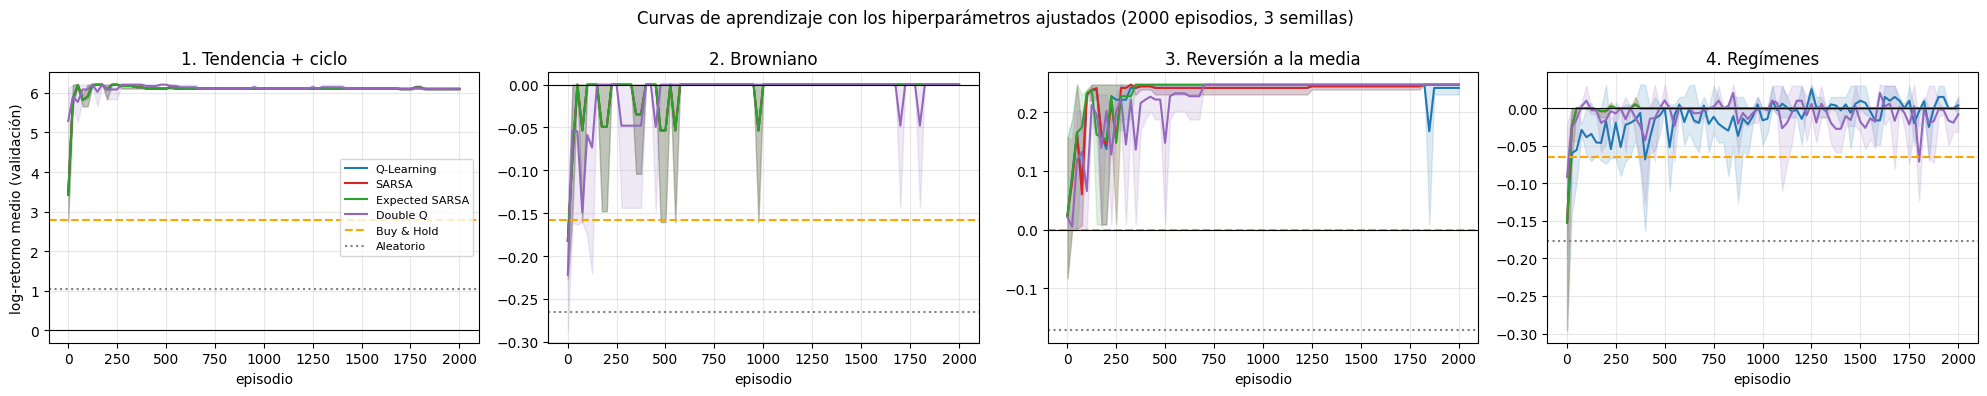

In [28]:
N_FINAL = 2000
PADRE = {"qlearning": "qlearning", "sarsa": "sarsa", "expected_sarsa": "sarsa", "doubleq": "qlearning"}

def cfg_final(alg, m, seed, **extra):
    h = MEJOR[(PADRE[alg], m)]
    return dict(metodo=alg, mercado=m, n_episodios=N_FINAL, seed=seed, alpha=h["alpha"], gamma=h["gamma"],
                **ESQUEMAS_EPS[h["esquema"]], **extra)

def exp_final():
    cfgs = [cfg_final(a, m, s) for a in COLORES for m in MERCADOS for s in range(3)]
    return lanzar(cfgs, test=True, eval_cada=25)

R_FINAL = cache("exp_final", exp_final)
plot_curvas(R_FINAL, f"Curvas de aprendizaje con los hiperparámetros ajustados ({N_FINAL} episodios, 3 semillas)")

### 3.1 Políticas aprendidas

Las acciones *vender* y *mantener* son equivalentes cuando no se tiene el activo (y *comprar* y *mantener* cuando sí se tiene), así que la forma más clara de leer la política es mostrar, para cada estado, **si el agente termina dentro o fuera del mercado** tras actuar. Cada celda indica la fracción de las 3 semillas en las que el agente está dentro del mercado (verde = dentro, rojo = fuera). Las columnas van de la tendencia más negativa (izquierda) a la más positiva (derecha).

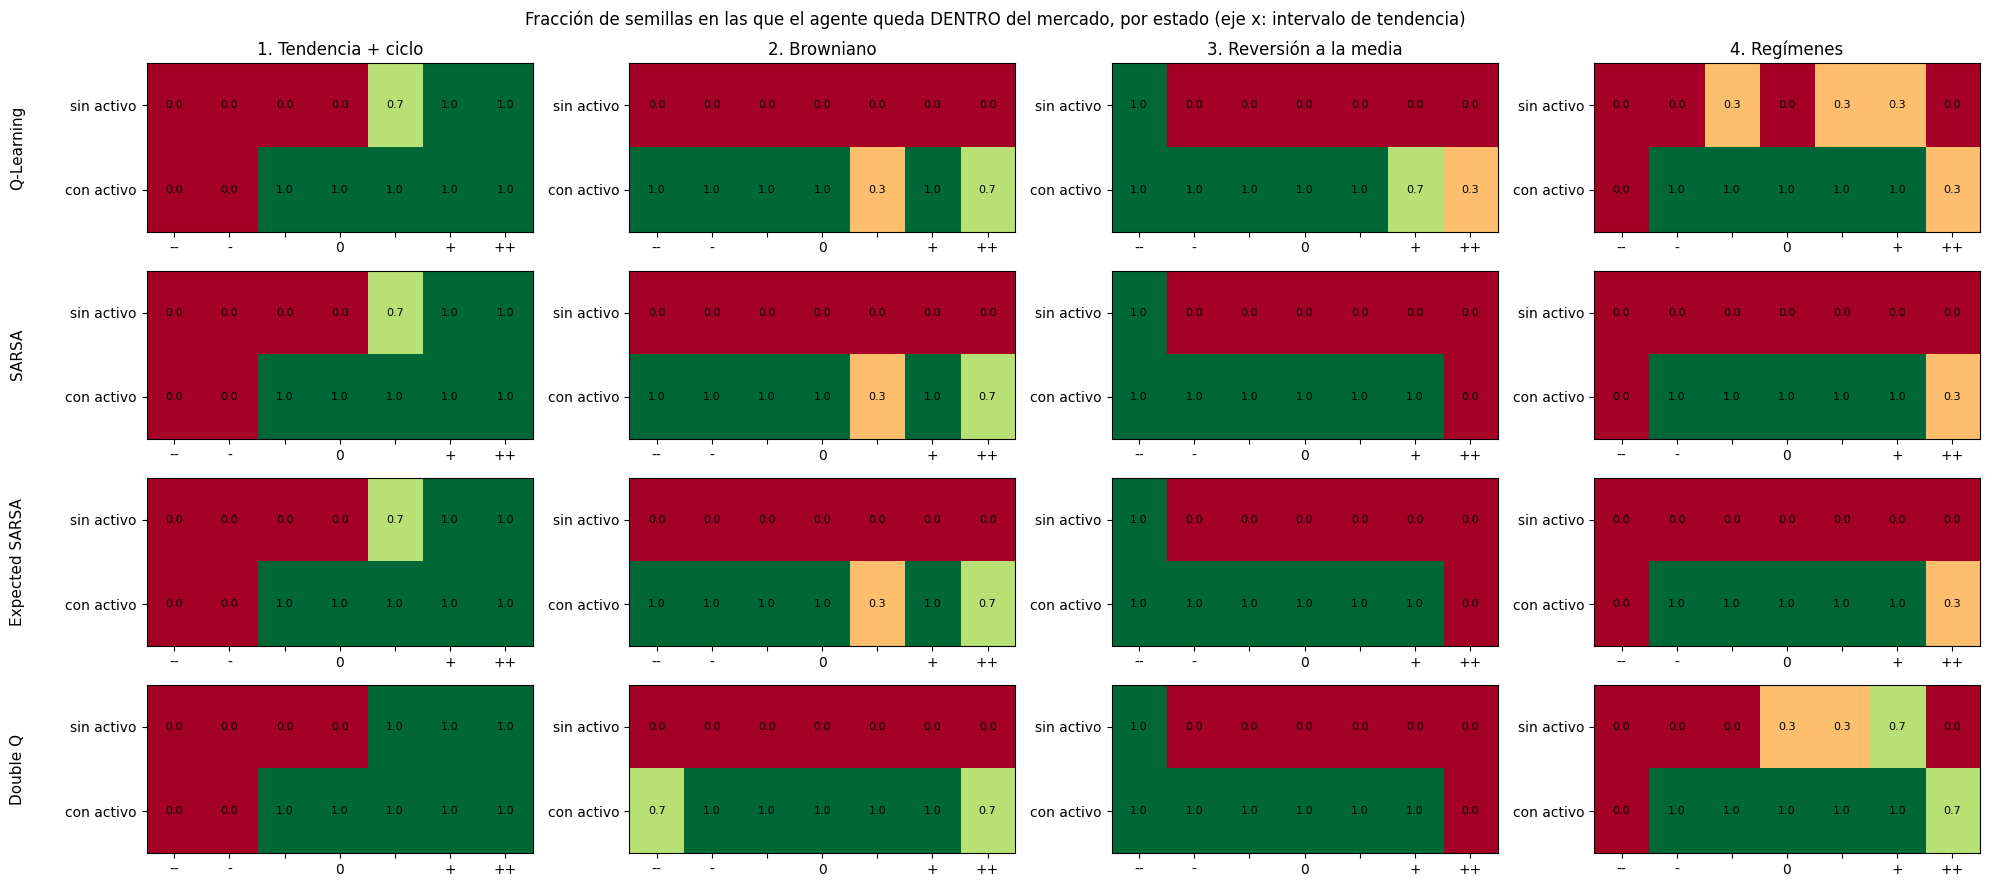

In [29]:
def dentro_tras_actuar(Q, n_bins):
    # Para cada estado (posición, intervalo): 1 si tras la acción greedy el agente posee el activo
    D = np.zeros((2, n_bins))
    for b in range(n_bins):
        for pos in (0, 1):
            a = int(np.argmax(Q[2 * b + pos]))
            D[pos, b] = 1.0 if (a == 2 or (pos == 1 and a == 1)) else 0.0
    return D

fig, axes = plt.subplots(4, 4, figsize=(20, 9))
for i, alg in enumerate(COLORES):
    for j, m in enumerate(MERCADOS):
        rs = [r for r in R_FINAL if r["cfg"]["metodo"] == alg and r["cfg"]["mercado"] == m]
        D = np.mean([dentro_tras_actuar(r["Q"], 7) for r in rs], axis=0)
        ax = axes[i, j]
        ax.imshow(D, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
        for (y, x), v in np.ndenumerate(D):
            ax.text(x, y, f"{v:.1f}", ha="center", va="center", fontsize=8)
        ax.set_yticks([0, 1], ["sin activo", "con activo"])
        ax.set_xticks(range(7), ["--", "-", "", "0", "", "+", "++"])
        ax.grid(False)
        if i == 0: ax.set_title(NOMBRES[m])
        if j == 0: ax.set_ylabel(ETIQUETAS[alg] + "\n\n", fontsize=11)
fig.suptitle("Fracción de semillas en las que el agente queda DENTRO del mercado, por estado (eje x: intervalo de tendencia)")
plt.tight_layout(); plt.show()

**Interpretación de las políticas.** Las políticas aprendidas son coherentes con la estructura de cada mercado, y además son **más sofisticadas que las reglas fijas** porque explotan la variable *posición* para crear **histéresis**:

* **Tendencia + ciclo → *momentum* con histéresis.** Sin activo, el agente sólo compra cuando la tendencia está en los intervalos más altos; con activo, sólo vende cuando la tendencia es claramente negativa (los dos primeros intervalos). En la zona intermedia **mantiene lo que tenga**. Así evita entrar y salir con cada pequeña fluctuación y paga muchas menos comisiones que la regla *momentum* (44 operaciones frente a 92 por episodio).
* **Browniano → no invertir.** El agente nunca compra (la fila "con activo" no importa porque ese estado no llega a visitarse con la política greedy). Es la respuesta racional a un mercado impredecible con comisiones: no hay ventaja que explotar y cada operación cuesta dinero.
* **Reversión a la media → *contrarian* extremo con histéresis.** Compra sólo en el intervalo de **tendencia más negativa** (el precio acaba de caer con fuerza, típicamente por debajo de su media) y mantiene hasta que la tendencia llega al **intervalo más positivo** (el precio ha rebotado), donde vende. Es la estrategia clásica de "comprar barato y vender caro", y es mucho más selectiva que la regla *contrarian* (que entra con cualquier tendencia negativa).
* **Regímenes → casi siempre fuera.** SARSA y Expected SARSA no invierten nunca. Q-Learning y Double Q (con $\gamma = 0.99$) entran ocasionalmente con tendencias moderadamente positivas y, una vez dentro, mantienen salvo en los extremos; pero las políticas varían entre semillas, señal de que no hay una ventaja clara con este estado.

Los cuatro algoritmos llegan a políticas casi idénticas en cada mercado. Con $\gamma = 0$ es inevitable (las actualizaciones coinciden); con $\gamma = 0.5$ (reversión) la ventaja de explotación es tan nítida que los cuatro convergen a lo mismo.

### 3.2 Distribución del rendimiento en test frente a los *baselines*

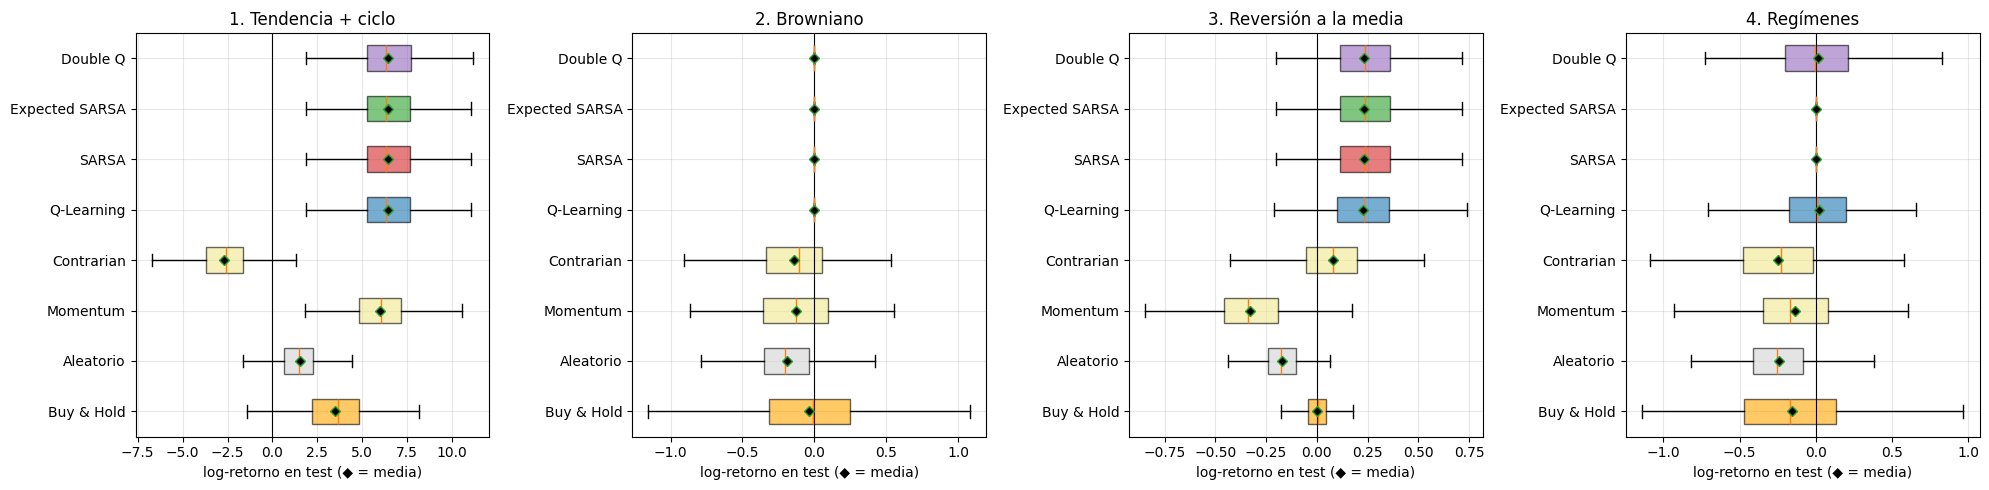

In [30]:
ESTRATEGIAS_BASE = {"buy_hold": "Buy & Hold", "aleatorio": "Aleatorio", "momentum": "Momentum", "contrarian": "Contrarian"}

def resultados_test(alg, m, res=R_FINAL):
    # Une los resultados de test de las 3 semillas (200 x 3 = 600 episodios)
    rs = [r["test"] for r in res if r["cfg"]["metodo"] == alg and r["cfg"]["mercado"] == m]
    return {k: np.concatenate([r[k] for r in rs]) for k in rs[0]}

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, m in zip(axes, MERCADOS):
    datos = [BASE_TEST[m][b]["log_ret"] for b in ESTRATEGIAS_BASE] + [resultados_test(a, m)["log_ret"] for a in COLORES]
    nombres = list(ESTRATEGIAS_BASE.values()) + [ETIQUETAS[a] for a in COLORES]
    bp = ax.boxplot(datos, vert=False, showfliers=False, patch_artist=True, showmeans=True,
                    meanprops=dict(marker="D", markerfacecolor="black", markersize=5))
    for patch, col in zip(bp["boxes"], ["orange", "lightgray", "khaki", "khaki"] + list(COLORES.values())):
        patch.set_facecolor(col); patch.set_alpha(0.6)
    ax.set_yticks(range(1, len(nombres) + 1), nombres)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(NOMBRES[m]); ax.set_xlabel("log-retorno en test (◆ = media)")
plt.tight_layout(); plt.show()

### 3.3 Un episodio de test de ejemplo en cada mercado

Misma figura que la del profesor, ahora con el agente Q-Learning entrenado (semilla 0) sobre la primera serie de test. Los puntos verdes indican que el agente posee el activo y los rojos que está en efectivo.

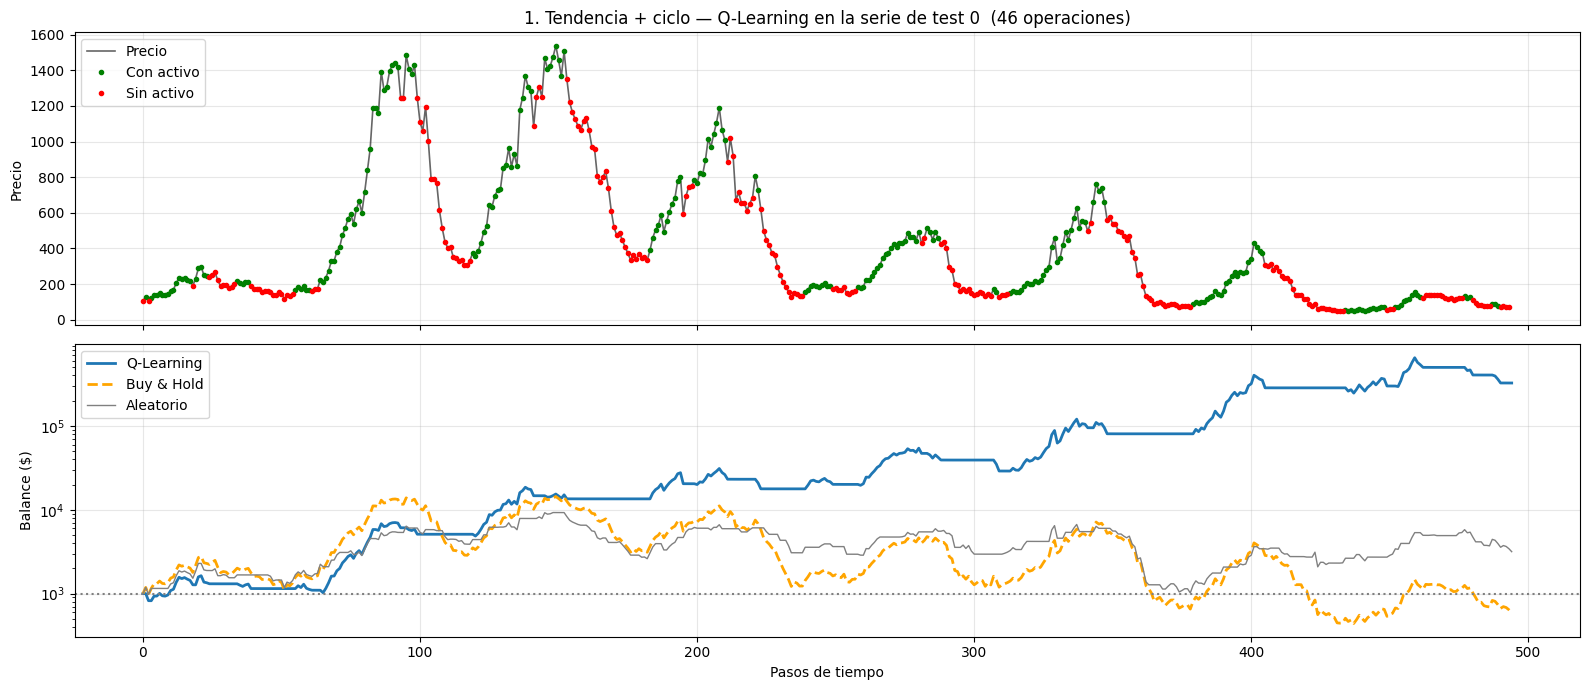

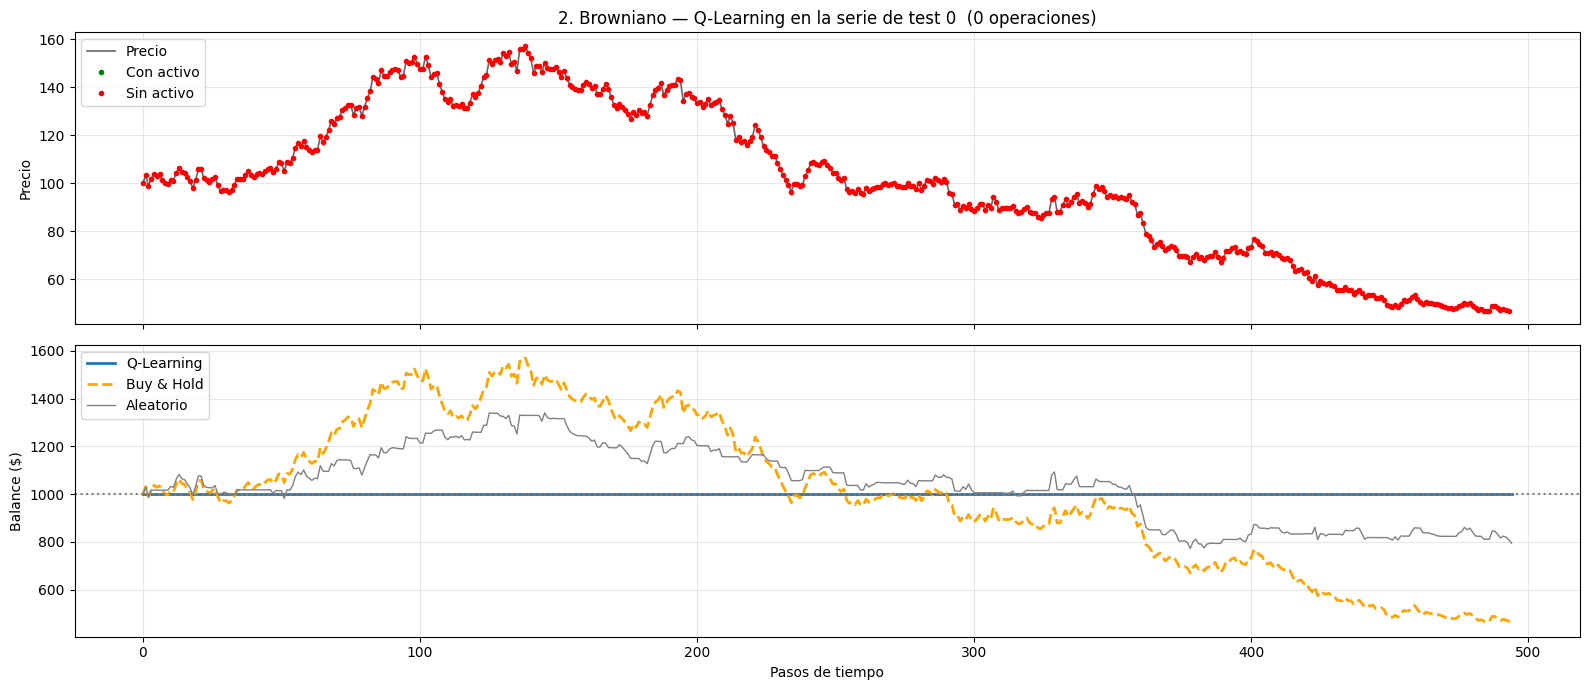

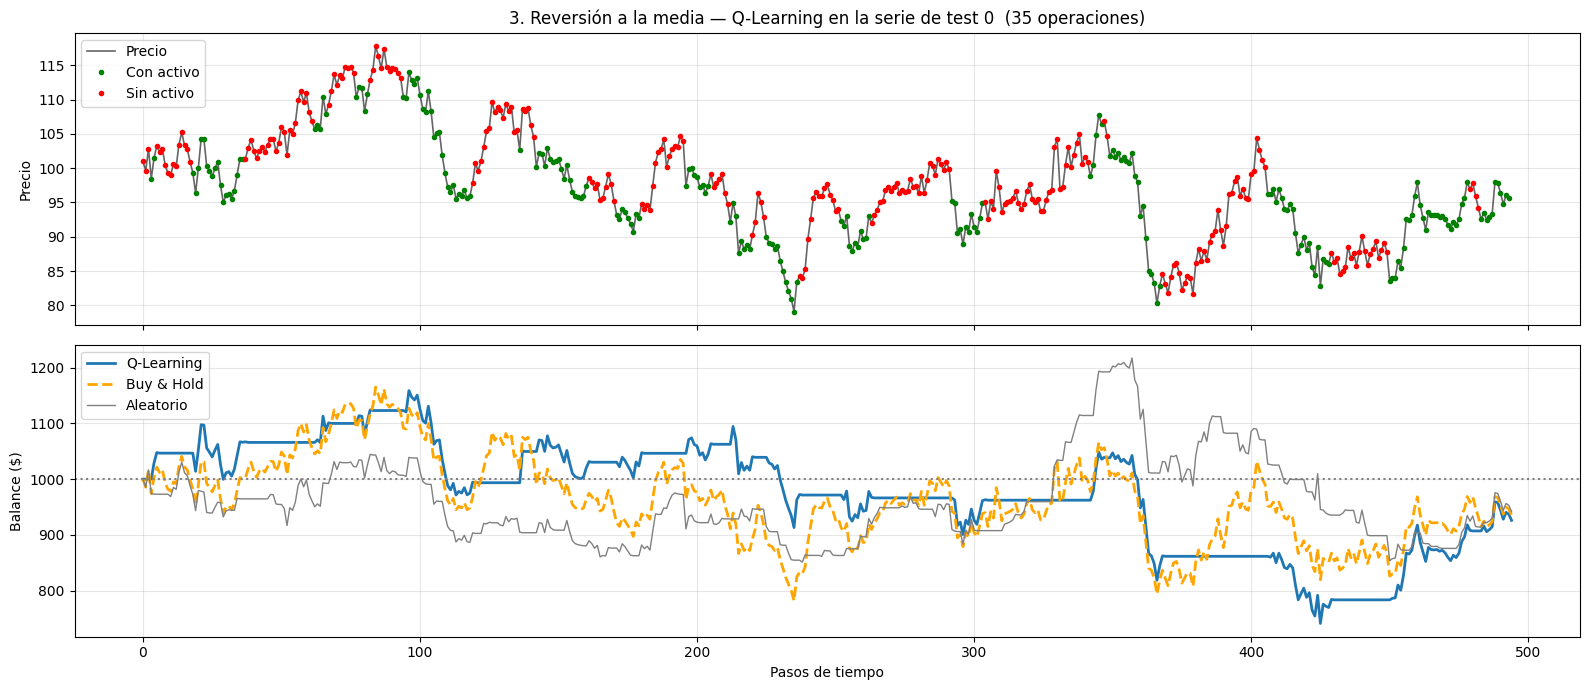

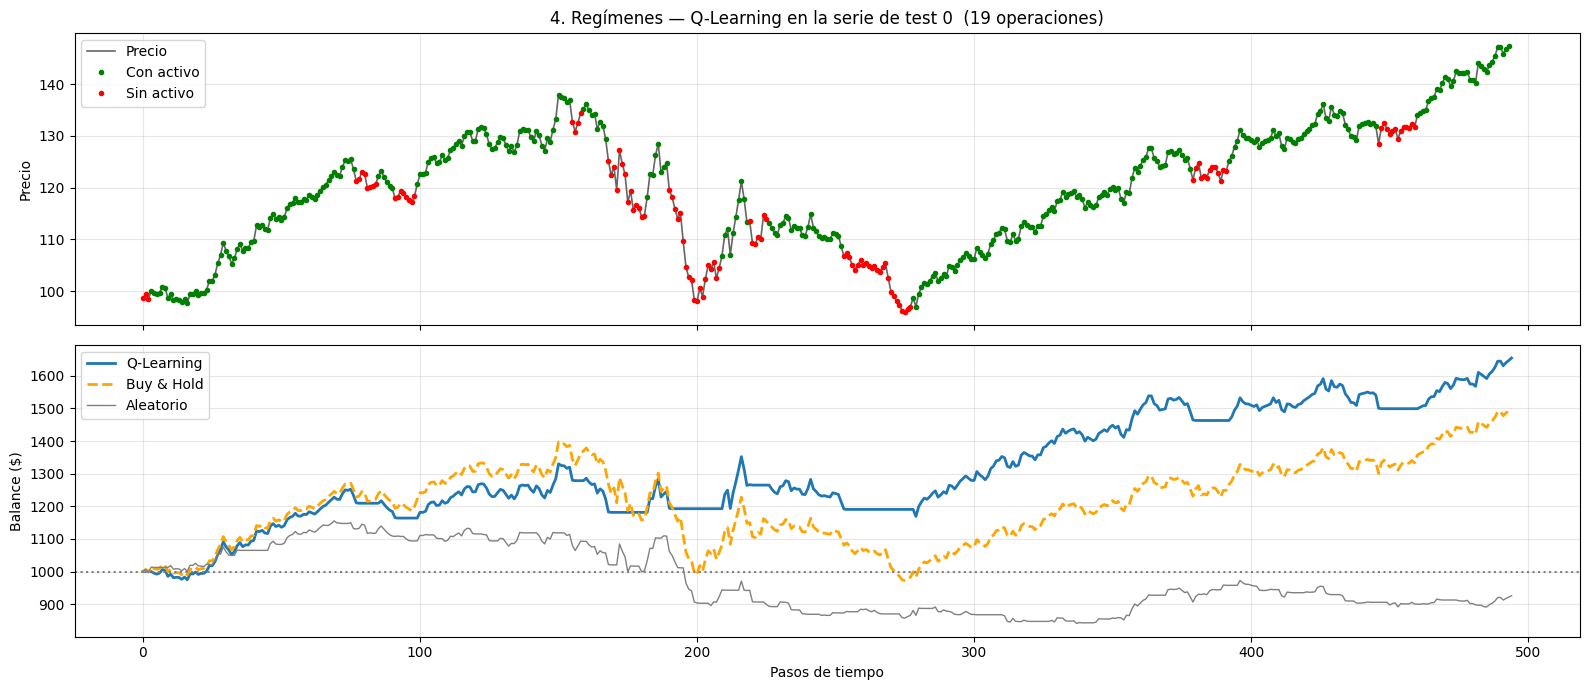

In [31]:
def plot_episodio(m, alg="qlearning", idx=0, seed=0):
    r = next(r for r in R_FINAL if r["cfg"]["metodo"] == alg and r["cfg"]["mercado"] == m and r["cfg"]["seed"] == seed)
    p = TEST[m][idx]
    _, disc = crear_estado(("tend", 7), m)
    ep = ejecutar_episodio(SimpleTradingEnv(p), AgenteCongelado(r["Q"]), disc, registrar=True)
    ep_rand = ejecutar_episodio(SimpleTradingEnv(p), PoliticaFija("aleatorio"), registrar=True)
    ep_bh = ejecutar_episodio(SimpleTradingEnv(p), PoliticaFija("buy_hold"), registrar=True)
    pv = p[5:-1]
    on, off = pv.copy(), pv.copy()
    on[ep["posiciones"] == 0] = np.nan
    off[ep["posiciones"] == 1] = np.nan

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
    ax1.plot(pv, color="black", alpha=0.6, lw=1.2, label="Precio")
    ax1.plot(on, "g.", label="Con activo"); ax1.plot(off, "r.", label="Sin activo")
    ax1.set_title(f"{NOMBRES[m]} — {ETIQUETAS[alg]} en la serie de test {idx}  ({ep['n_ops']} operaciones)")
    ax1.set_ylabel("Precio"); ax1.legend(loc="upper left")
    ax2.plot(ep["balances"], color="tab:blue", lw=2, label=ETIQUETAS[alg])
    ax2.plot(ep_bh["balances"], color="orange", ls="--", lw=2, label="Buy & Hold")
    ax2.plot(ep_rand["balances"], color="gray", lw=1, label="Aleatorio")
    ax2.axhline(1000, color="gray", ls=":")
    if m == "ciclo": ax2.set_yscale("log")
    ax2.set_ylabel("Balance ($)"); ax2.set_xlabel("Pasos de tiempo"); ax2.legend(loc="upper left")
    plt.tight_layout(); plt.show()

for m in MERCADOS:
    plot_episodio(m)

**Interpretación del análisis (Ejercicio 2): ¿es la estrategia encontrada la esperada?**

| Mercado | Estrategia esperada | Estrategia aprendida | ¿Coincide? |
|---|---|---|---|
| Tendencia + ciclo | Seguir la tendencia (*momentum*) | *Momentum* con histéresis | **Sí**, y mejora la regla fija (6.42 frente a 6.00 de log-retorno en test, ≈ ×610 frente a ×400 el capital) |
| Browniano | No hay ventaja: no operar o *buy & hold* | No operar | **Sí**. Gana al B&H en log-retorno (0 frente a −0.04) porque evita el arrastre de la volatilidad, aunque la diferencia no es significativa |
| Reversión a la media | Comprar tras caídas, vender tras subidas (*contrarian*) | *Contrarian* sólo en los extremos, con histéresis | **Sí**, y triplica a la regla fija (0.23 frente a 0.08) |
| Regímenes | Estar dentro en régimen alcista y fuera en el bajista | Mayoritariamente fuera | **Parcialmente**: el agente no puede identificar el régimen con la tendencia de 6 pasos, y elige la mejor alternativa disponible (no invertir), que supera a todos los *baselines*. Con un estado más informativo sí aprende la estrategia esperada (sección 5.2) |

En los episodios de ejemplo se ve el comportamiento descrito: en el mercado cíclico el agente está dentro durante las fases alcistas del ciclo y fuera en las bajistas; en reversión a la media compra en los valles y vende en los picos. Conviene recordar que un episodio aislado no es representativo (en la serie de test 0 de reversión, por ejemplo, el agente acaba ligeramente por debajo del *buy & hold*); las conclusiones se basan en las 200 series de test.

El diagrama de cajas muestra además que los agentes **reducen el riesgo**: en todos los mercados su dispersión de resultados y su *drawdown* máximo son menores que los del *buy & hold* (por ejemplo, en el mercado cíclico la mediana del *drawdown* baja del 90 % al 61 %), porque pasan buena parte del tiempo fuera del mercado en las fases desfavorables.

## 4. Tabla comparativa (Ejercicio 4)

Para cada mercado y estrategia (200 series de test; en los agentes, además, 3 semillas → 600 episodios):

* **Log-ret medio**: media de $\log(B_T/B_0)$; **σ semillas**: desviación típica entre las 3 semillas del log-retorno medio (robustez del entrenamiento).
* **Rent. geom. (%)**: $e^{\overline{\log r}} - 1$.
* **Balance mediano**: balance final mediano partiendo de 1000 $.
* **% > B&H**: porcentaje de series de test en las que la estrategia acaba con más dinero que el *buy & hold*.
* **MaxDD (%)**: *drawdown* máximo mediano. **Ops**: operaciones (compras + ventas) medianas por episodio. **% dentro**: tiempo medio con el activo.
* **Ep. conv.**: episodio a partir del cual la curva de aprendizaje (validación, suavizada) se mantiene dentro de una banda del ±10 % del rango total de la curva alrededor de su valor final. **t conv. (s)**: el mismo dato en segundos de entrenamiento. **t total (s)**: tiempo de los `N_FINAL` episodios.

In [32]:
def episodio_convergencia(curva, tol_rel=0.10, tol_abs=0.005):
    x, y = curva[:, 0], curva[:, 1]
    y = pd.Series(y).rolling(3, min_periods=1, center=True).mean().values  # suavizado ligero
    final = y[-max(3, len(y) // 10):].mean()
    tol = max(tol_rel * (y.max() - y.min()), tol_abs)
    fuera = np.flatnonzero(np.abs(y - final) > tol)
    return x[0] if len(fuera) == 0 else x[min(fuera[-1] + 1, len(x) - 1)]


def fila_tabla(m, nombre, res, bh, extra=None):
    f = {"Mercado": NOMBRES[m], "Estrategia": nombre,
         "Log-ret medio": res["log_ret"].mean(),
         "Rent. geom. (%)": 100 * (np.exp(res["log_ret"].mean()) - 1),
         "Balance mediano": np.median(res["balance"]),
         "% > B&H": 100 * np.mean(res["balance"] > np.tile(bh, len(res["balance"]) // len(bh))),
         "MaxDD (%)": 100 * np.median(res["max_dd"]),
         "Ops": np.median(res["n_ops"]),
         "% dentro": 100 * res["t_dentro"].mean()}
    f.update(extra or {})
    return f


def tabla_comparativa(res_final=R_FINAL, algoritmos=COLORES, etiquetas=ETIQUETAS):
    filas = []
    for m in MERCADOS:
        bh = BASE_TEST[m]["buy_hold"]["balance"]
        for b, nombre in ESTRATEGIAS_BASE.items():
            filas.append(fila_tabla(m, nombre, BASE_TEST[m][b], bh))
        for a in algoritmos:
            rs = [r for r in res_final if r["cfg"]["metodo"] == a and r["cfg"]["mercado"] == m]
            if not rs:
                continue
            conv = np.array([episodio_convergencia(r["curva"]) for r in rs])
            extra = {"σ semillas": np.std([r["test"]["log_ret"].mean() for r in rs]),
                     "Ep. conv.": conv.mean(),
                     "t conv. (s)": np.mean([c * r["t_por_ep"] for c, r in zip(conv, rs)]),
                     "t total (s)": np.mean([r["tiempo"] for r in rs])}
            filas.append(fila_tabla(m, etiquetas[a], resultados_test(a, m, res_final), bh, extra))
    return pd.DataFrame(filas).set_index(["Mercado", "Estrategia"])

TABLA = tabla_comparativa()
TABLA.to_csv(os.path.join(DIR_RES, "tabla_comparativa.csv"))

fmt = {"Log-ret medio": "{:.3f}", "σ semillas": "{:.3f}", "Rent. geom. (%)": "{:,.1f}", "Balance mediano": "{:,.0f}",
       "% > B&H": "{:.0f}", "MaxDD (%)": "{:.1f}", "Ops": "{:.0f}", "% dentro": "{:.0f}",
       "Ep. conv.": "{:.0f}", "t conv. (s)": "{:.1f}", "t total (s)": "{:.1f}"}
(TABLA.style.format(fmt, na_rep="—")
      .apply(lambda c: ["font-weight: bold" if v == c.loc[i[0]].max() else "" for i, v in c.items()]
             if c.name == "Log-ret medio" else [""] * len(c), axis=0))

In [33]:
# Significación estadística: test de Wilcoxon pareado (por serie de test) del mejor agente frente a B&H y a "quedarse fuera" (0)
from scipy.stats import wilcoxon

filas = []
for m in MERCADOS:
    bh = BASE_TEST[m]["buy_hold"]["log_ret"]
    for a in ["qlearning", "sarsa"]:
        rs = [r for r in R_FINAL if r["cfg"]["metodo"] == a and r["cfg"]["mercado"] == m]
        lr = np.mean([r["test"]["log_ret"] for r in rs], axis=0)   # media de las 3 semillas por serie
        filas.append({"Mercado": NOMBRES[m], "Algoritmo": ETIQUETAS[a],
                      "Δ vs B&H": (lr - bh).mean(),
                      "p-valor vs B&H": wilcoxon(lr, bh).pvalue if np.any(lr != bh) else 1.0,
                      "p-valor vs 0": wilcoxon(lr).pvalue if np.any(lr != 0) else 1.0})
pd.DataFrame(filas).set_index(["Mercado", "Algoritmo"]).style.format({"Δ vs B&H": "{:+.3f}", "p-valor vs B&H": "{:.1e}", "p-valor vs 0": "{:.1e}"})

**Interpretación de la tabla (Ejercicio 4).**

**Rendimiento.**

* Los agentes RL son la **mejor estrategia en los cuatro mercados**. Superan al *buy & hold* en el 98 % de las series del mercado cíclico y en el 84 % de las de reversión a la media. El test de Wilcoxon pareado confirma que la mejora frente al *buy & hold* es estadísticamente significativa en los mercados 1, 3 y 4 ($p < 10^{-5}$), pero **no en el browniano** ($p = 0.36$), como cabe esperar en un mercado sin estructura.
* En **regímenes** la mejora frente al *buy & hold* es significativa, pero el log-retorno de Q-Learning (+0.018) **no es significativamente distinto de 0** ($p = 0.54$): el agente gana al mercado porque evita las pérdidas, no porque obtenga beneficios.
* **Los cuatro algoritmos rinden prácticamente igual** en cada mercado. Con los hiperparámetros elegidos ($\gamma = 0$ en tres casos para SARSA) muchas de sus actualizaciones coinciden, y el problema es lo bastante simple (42 valores $Q$, transiciones exógenas) como para que el *target* concreto no marque la diferencia. La única excepción es regímenes, donde Q-Learning y Double Q (con $\gamma = 0.99$) invierten algo y SARSA (con $\gamma = 0$ por empate) no.
* La **σ entre semillas** es muy pequeña (≤ 0.02): el entrenamiento es reproducible.

**Convergencia.**

* Con los hiperparámetros ajustados los agentes convergen en **unos cientos de episodios** (≈ 80-850, de 2 a 30 s de CPU). El mercado cíclico es el más rápido (~80 episodios, ~2 s) porque su señal es la más fuerte. En reversión, Q-Learning aparece con una convergencia tardía (~790) porque una semilla sufre una caída puntual cerca del episodio 1850 (visible en la curva), de nuevo por la fragilidad de la decisión de compra.
* **Double Q-Learning converge más despacio** que Q-Learning en el mercado cíclico (450 frente a 83 episodios) y en el browniano (842 frente a 525), y su curva es más irregular en todos: cada transición actualiza sólo una de sus dos tablas, de modo que cada tabla ve la mitad de los datos. En este problema el sesgo de sobreestimación que corrige no es relevante (3 acciones, valores muy próximos), así que paga el coste sin obtener beneficio.
* **Expected SARSA** es un 20-27 % más lento **por episodio** (calcula la esperanza sobre las acciones en cada paso), sin mejorar el resultado.
* En **regímenes**, Q-Learning y Double Q no llegan a estabilizarse (episodio de convergencia ≈ 1800-2000): su curva de validación sigue oscilando alrededor de 0 porque la política alterna entre variantes con valores casi empatados. Es coherente con la ausencia de una señal clara en ese estado.

## 5. Pruebas adicionales

### 5.1 Granularidad de la discretización

¿Cuántos intervalos de tendencia conviene usar? Pocos intervalos pierden información; muchos dividen los datos y cada $Q(s,a)$ se estima con menos muestras (más varianza). Probamos Q-Learning con 3, 5, 7, 11 y 15 intervalos (con los hiperparámetros ajustados, 2 semillas, validación).

In [34]:
N_BINS = [3, 5, 7, 11, 15]

def exp_bins():
    cfgs = [dict(cfg_final("qlearning", m, s), n_episodios=1500, estado=("tend", nb))
            for m in MERCADOS for nb in N_BINS for s in range(2)]
    return lanzar(cfgs, val=True)

R_BINS = cache("exp_bins", exp_bins)
df_bins = pd.DataFrame([dict(mercado=NOMBRES[r["cfg"]["mercado"]], n_bins=r["cfg"]["estado"][1],
                             log_ret=r["val"]["log_ret"].mean()) for r in R_BINS])
df_bins.groupby(["mercado", "n_bins"])["log_ret"].mean().unstack().style.format("{:.3f}") \
       .highlight_max(axis=1, color="#c6efce").set_caption("Q-Learning: log-retorno medio en validación según nº de intervalos")

n_bins,3,5,7,11,15
mercado,,,,,
1. Tendencia + ciclo,6.531,6.628,6.647,6.679,6.686
2. Browniano,0.000,0.000,0.000,0.000,0.000
3. Reversión a la media,0.000,0.163,0.189,0.214,0.232
4. Regímenes,0.000,0.000,0.014,0.052,0.052


**Interpretación.** Más intervalos **mejoran** el resultado en todos los mercados con estructura, especialmente en reversión a la media (0 con 3 intervalos → 0.23 con 15) y en regímenes (0 → 0.05). La razón es que **la información útil está en las colas**: las caídas o subidas extremas son las que predicen el movimiento siguiente, y con pocos intervalos las tendencias extremas quedan mezcladas con las moderadas, diluyendo la señal hasta hacerla inferior a la comisión. Con 3 intervalos en reversión el agente ya no encuentra ningún estado donde comprar compense.

No se observa todavía el efecto contrario (demasiados estados con pocas muestras cada uno) porque cada episodio aporta ~500 transiciones y, incluso con 15 intervalos (30 estados), cada estado recibe muchas visitas. Por coherencia con el resto del trabajo se ha mantenido `n_bins = 7`, pero estos resultados indican que una partición más fina (11-15) sería una mejora directa.

### 5.2 Estado ampliado con la volatilidad reciente

El estado del enunciado sólo contiene la tendencia de corto plazo. En el mercado de regímenes, sin embargo, lo que distingue un régimen alcista de uno bajista no es tanto la tendencia de 6 pasos (muy ruidosa) como la **volatilidad**: 1 % por paso en el alcista frente a 2.5 % en el bajista. Probamos un estado `(tendencia, volatilidad, posición)` con 5 intervalos de tendencia × 3 de volatilidad × 2 posiciones = 30 estados (`TradingEnvVol`, definido en la sección 1), manteniendo los mismos hiperparámetros.

In [35]:
def exp_vol():
    cfgs = [cfg_final(a, m, s, estado=("vol", 5, 3)) for a in ["qlearning", "sarsa"] for m in MERCADOS for s in range(3)]
    return lanzar(cfgs, test=True, eval_cada=25)

R_VOL = cache("exp_vol", exp_vol)

filas = []
for m in MERCADOS:
    filas.append({"Mercado": NOMBRES[m], "Estrategia": "Buy & Hold", "Log-ret medio": BASE_TEST[m]["buy_hold"]["log_ret"].mean()})
    for a in ["qlearning", "sarsa"]:
        for nombre, res in [("estado base", R_FINAL), ("estado + volatilidad", R_VOL)]:
            t = resultados_test(a, m, res)
            filas.append({"Mercado": NOMBRES[m], "Estrategia": f"{ETIQUETAS[a]} ({nombre})", "Log-ret medio": t["log_ret"].mean(),
                          "% dentro": 100 * t["t_dentro"].mean(), "Ops": np.median(t["n_ops"])})
pd.DataFrame(filas).set_index(["Mercado", "Estrategia"]).style.format("{:.3f}", subset=["Log-ret medio"]) \
  .format("{:.0f}", subset=["% dentro", "Ops"], na_rep="—")

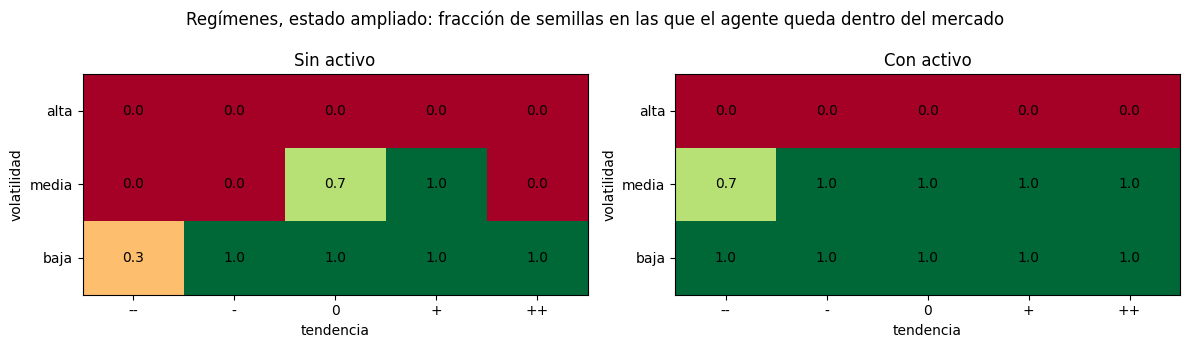

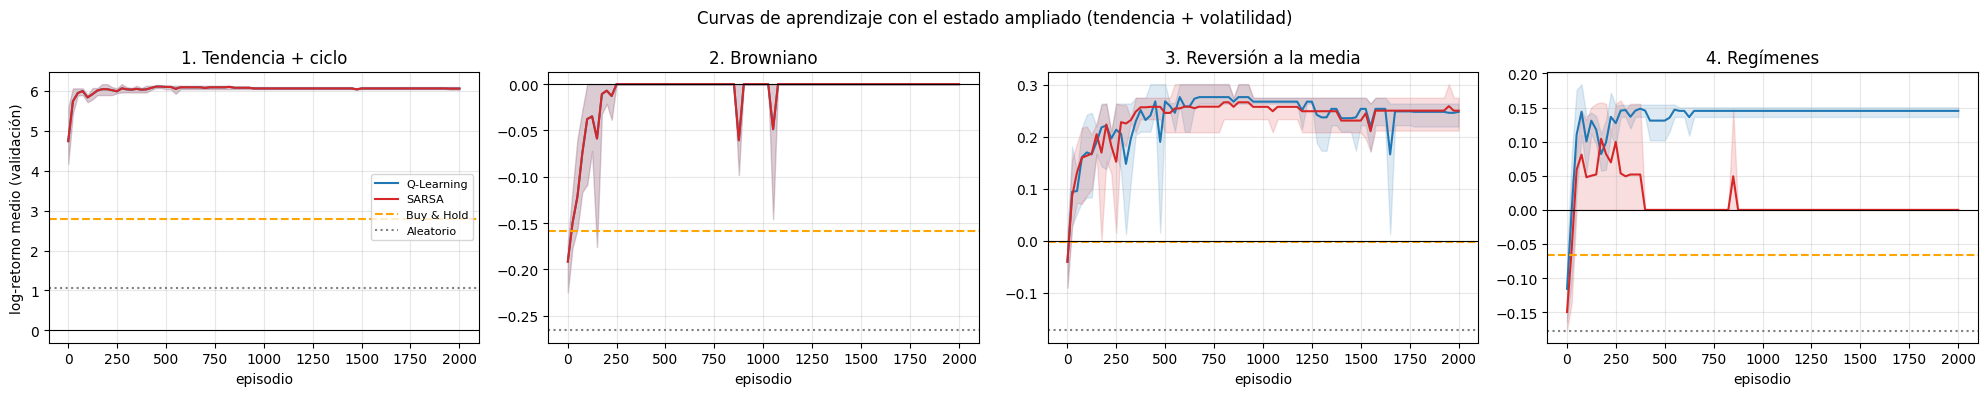

In [36]:
# Política aprendida en el mercado de regímenes con el estado ampliado (Q-Learning, media de 3 semillas)
rs = [r for r in R_VOL if r["cfg"]["metodo"] == "qlearning" and r["cfg"]["mercado"] == "regimenes"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for pos, ax in zip((0, 1), axes):
    D = np.zeros((3, 5))
    for r in rs:
        for bt in range(5):
            for bv in range(3):
                a = int(np.argmax(r["Q"][2 * (bt * 3 + bv) + pos]))
                D[bv, bt] += (a == 2 or (pos == 1 and a == 1)) / len(rs)
    ax.imshow(D, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto", origin="lower")
    for (y, x), v in np.ndenumerate(D):
        ax.text(x, y, f"{v:.1f}", ha="center", va="center")
    ax.set_xticks(range(5), ["--", "-", "0", "+", "++"]); ax.set_xlabel("tendencia")
    ax.set_yticks(range(3), ["baja", "media", "alta"]); ax.set_ylabel("volatilidad")
    ax.set_title(["Sin activo", "Con activo"][pos]); ax.grid(False)
fig.suptitle("Regímenes, estado ampliado: fracción de semillas en las que el agente queda dentro del mercado")
plt.tight_layout(); plt.show()

plot_curvas([r for r in R_VOL], "Curvas de aprendizaje con el estado ampliado (tendencia + volatilidad)")

**Interpretación.** Añadir la volatilidad al estado **transforma el resultado en el mercado de regímenes**: Q-Learning pasa de un log-retorno de +0.02 a **+0.13** (frente a −0.15 del *buy & hold*), y las tres semillas obtienen prácticamente lo mismo. La política aprendida es exactamente la que dicta el modelo generador: **dentro del mercado cuando la volatilidad es baja (régimen alcista) y fuera cuando es alta (régimen bajista)**, prácticamente sin importar la tendencia. Con volatilidad media (zona ambigua) aparece de nuevo la histéresis: si ya tiene el activo lo mantiene, y si no lo tiene sólo compra con tendencia neutra o positiva. El agente ha "descubierto" que la volatilidad es un buen detector de régimen.

Dos observaciones críticas:

* **SARSA no se beneficia** porque su $\gamma$ quedó fijado en 0 por un empate en la rejilla (todas las configuraciones daban 0 con el estado base). Un agente miope no puede aprender esta estrategia: la ganancia esperada de un paso en régimen alcista (+0.1 %) es igual a la comisión de compra (0.1 %), así que comprar sólo compensa si se valoran los pasos futuros. Es un ejemplo claro de que **los hiperparámetros óptimos dependen de la representación del estado**: al cambiar el estado habría que volver a ajustarlos.
* En los otros mercados el estado ampliado **no cambia nada relevante** (la volatilidad no aporta información en ellos), lo que confirma que la mejora en regímenes no es casualidad. El precio a pagar es un espacio de estados mayor (30 frente a 14), que aquí no supone problema.

### 5.3 Generalización entre mercados

Cada agente se ha entrenado con un único tipo de mercado. ¿Qué ocurre si lo usamos en otro? Evaluamos los agentes Q-Learning finales (3 semillas) de cada mercado sobre las series de test de los demás. El agente conserva **su** discretizador (el ajustado en su mercado de entrenamiento), como ocurriría en un despliegue real. Se muestra la diferencia de log-retorno respecto al *buy & hold* del mercado de test.

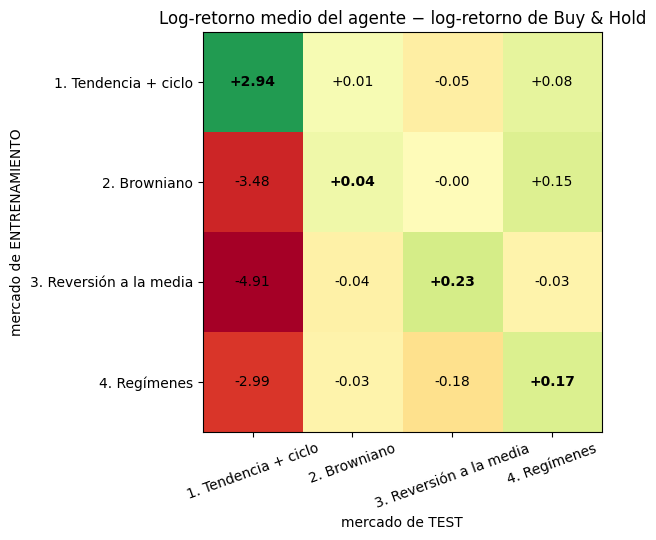

In [37]:
def exp_cruzado():
    M = np.zeros((4, 4))
    for i, m_train in enumerate(MERCADOS):
        _, disc = crear_estado(("tend", 7), m_train)
        rs = [r for r in R_FINAL if r["cfg"]["metodo"] == "qlearning" and r["cfg"]["mercado"] == m_train]
        for j, m_test in enumerate(MERCADOS):
            lr = np.mean([evaluar(AgenteCongelado(r["Q"]), TEST[m_test], disc)["log_ret"].mean() for r in rs])
            M[i, j] = lr - BASE_TEST[m_test]["buy_hold"]["log_ret"].mean()
    return M

M_CRUZ = cache("exp_cruzado", exp_cruzado)
fig, ax = plt.subplots(figsize=(7, 5.5))
lim = np.abs(M_CRUZ).max()
ax.imshow(np.sign(M_CRUZ) * np.sqrt(np.abs(M_CRUZ)), cmap="RdYlGn", vmin=-np.sqrt(lim), vmax=np.sqrt(lim))
for (y, x), v in np.ndenumerate(M_CRUZ):
    ax.text(x, y, f"{v:+.2f}", ha="center", va="center", fontweight="bold" if x == y else None)
ax.set_xticks(range(4), [NOMBRES[m] for m in MERCADOS], rotation=20); ax.set_xlabel("mercado de TEST")
ax.set_yticks(range(4), [NOMBRES[m] for m in MERCADOS]); ax.set_ylabel("mercado de ENTRENAMIENTO")
ax.set_title("Log-retorno medio del agente − log-retorno de Buy & Hold"); ax.grid(False)
plt.tight_layout(); plt.show()

**Interpretación.** La diagonal (cada agente en su propio mercado) es positiva, pero **fuera de ella los agentes no generalizan**:

* Cualquier agente entrenado en un mercado "tranquilo" y aplicado al mercado cíclico pierde enormemente frente al *buy & hold* (−3 a −5 de log-retorno): sus intervalos de tendencia están calibrados para variaciones de ±4 %, así que las tendencias del mercado cíclico (±20 %) caen siempre en los intervalos extremos, y además sus reglas (no invertir, *contrarian*...) son opuestas a lo que funciona en ese mercado.
* El agente de **reversión** aplicado a **regímenes** queda 0.18 por debajo del B&H (que ya pierde), porque compra tras las caídas, que en un mercado con inercia bajista es precisamente lo que no hay que hacer.
* Los agentes cuya política es "no invertir" (browniano) obtienen siempre 0, que resulta bueno o malo según si el *buy & hold* de ese mercado pierde o gana.

Es decir, el agente aprende **las regularidades específicas del proceso generador** con el que se entrena, no una "habilidad general" de inversión. En un mercado real, donde el proceso generador cambia con el tiempo, esto obligaría a reentrenar periódicamente o a entrenar con una mezcla de regímenes.

## 6. Conclusiones y análisis crítico

**Resultados principales**

1. Q-Learning y SARSA tabulares, con una discretización adecuada del estado y un $\alpha$ pequeño, aprenden en todos los mercados una política **igual o mejor que la mejor regla fija** y siempre mejor que el *buy & hold* y que el agente aleatorio: *momentum* con histéresis en el mercado cíclico (log-retorno 6.42 frente a 3.48 del B&H), *contrarian* extremo en reversión a la media (0.23 frente a 0.00), y no invertir en los mercados sin ventaja explotable (browniano y regímenes).
2. Las políticas son **interpretables** y coinciden con lo que la teoría del proceso generador predice. El agente explota además una idea que las reglas fijas no tienen: la **histéresis** (decidir distinto según si ya se posee el activo), que reduce las operaciones a la mitad o menos (44 frente a 92 en el ciclo, 36 frente a 126 en reversión) y, por tanto, las comisiones.
3. El hiperparámetro decisivo es **$\alpha$**: la ventaja explotable (~0.1 %/paso) es diminuta frente al ruido (1-10 %/paso), y sólo con $\alpha \lesssim 0.005$ (o decreciente con las visitas) se estiman bien los valores. **$\gamma$** debe ajustarse al horizonte de la señal: 0 si la predicción es de un paso y mayor que la comisión (ciclo), $\geq 0.5$ si el beneficio llega en varios pasos (reversión), $\approx 0.99$ si la señal es persistente (regímenes). La **exploración** apenas influye porque las acciones no afectan a la dinámica del mercado, y el aprendizaje converge en **unos cientos de episodios**.
4. Las diferencias entre Q-Learning, SARSA, Expected SARSA y Double Q son **despreciables** en este problema: con $\gamma = 0$ son el mismo algoritmo, y el espacio de estados es demasiado pequeño para que la varianza o el sesgo del *target* importen. Double Q converge más lento y Expected SARSA es más caro por paso, sin ventaja alguna.
5. El factor limitante es la **representación del estado**, no el algoritmo: más intervalos de tendencia mejoran los resultados, y añadir la volatilidad permite detectar los regímenes y pasar de +0.02 a +0.13 en ese mercado.

**Limitaciones y análisis crítico**

* **Recompensa frente a objetivo.** La recompensa del entorno es la suma de retornos aritméticos, pero el capital crece geométricamente. El agente optimiza $\sum r_t$ y no $\log(B_T/B_0)$; en mercados con mucha volatilidad (browniano con $\gamma$ alto) esto lleva a mantener posiciones con log-retorno esperado negativo. Una recompensa $\log(B_{t+1}/B_t)$ estaría mejor alineada con el objetivo real.
* **Fragilidad de la decisión.** Las estrategias rentables dependen de diferencias de $Q$ del orden de 0.001-0.002. Pequeñas fluctuaciones (semillas, $\alpha$ constante) pueden cambiar la política, como se vio en reversión con 4000 episodios. Un $\alpha$ decreciente al final del entrenamiento o promediar varias semillas daría políticas más estables.
* **Selección de hiperparámetros con empates.** Cuando muchas configuraciones dan 0, la elegida es arbitraria; así SARSA quedó con $\gamma = 0$ en regímenes y no pudo aprovechar el estado ampliado. Además, los hiperparámetros se ajustaron con el estado base y se reutilizaron en las variantes (Expected SARSA, Double Q, estado con volatilidad); un ajuste específico podría mejorarlas.
* **Datos sintéticos.** El mercado cíclico tiene siempre la misma fase y el mismo periodo, una regularidad que ningún mercado real ofrece, y la evaluación cruzada muestra que los agentes no generalizan fuera del proceso con el que se entrenan. En datos reales habría que añadir costes más realistas (*spread*, deslizamiento), validación temporal (*walk-forward*) y reentrenamiento periódico.
* **Posibles extensiones:** recompensa logarítmica; más información en el estado (tendencias a varias escalas, distancia a una media larga, volatilidad); posiciones cortas o fraccionarias; aproximación de funciones (*tile coding* o redes neuronales, DQN) para trabajar con el estado continuo sin discretizar; y prueba con series reales.